# Hill Climbing and Simulated Annealing for the Travelling Salesman Problem

This notebook applies five hill-climbing methods and simulated annealing to the **Travelling Salesman Problem (TSP)** using the 50 cities in `cities 2.csv`.

| # | Method | Idea |
|---|---|---|
| 1 | **Simple hill climbing** | Move to the *first* neighbour that is better |
| 2 | **Steepest-ascent hill climbing** | Examine *all* neighbours, move to the *best* one |
| 3 | **Stochastic hill climbing** | Choose *at random* among the neighbours that are better |
| 4 | **Random-restart hill climbing** | Run a hill climber from many random starts, keep the best |
| 5 | **Iterated local search (ILS)** | Local search → perturb → local search → accept if better … |
| 6 | **Simulated annealing (SA)** | Random neighbour; always accept better, sometimes accept worse (less often as the temperature falls) |

The structure follows the hill climbers in the module notebook: start from a random solution, generate a neighbour, and only accept it if the evaluation improves. Because a shorter route is better, this is a **minimisation** problem.

**Notebook layout**
* Sections 1–8 explain the problem and each method, with a demonstration run on all 50 cities.
* Section 9 describes the **methodology**: problem instances, parameter tuning, repeated runs and the statistical tests used.
* Sections 10–16 are the **experiments required by the assessment brief**: every algorithm is tested on 10, 20, 30, 40 and 50 cities with repeated runs, and compared on solution quality, runtime, convergence, robustness, scalability and statistical significance.
* Section 17 discusses the results.
* Each algorithm's parameters are in a **parameter cell directly above its implementation**, so they are easy to change.
* All outputs (CSV tables, tuned parameters, figures for the report) are written to the `results/` folder.
* Further algorithms can be added in **section 9.4** and they are automatically included in every table and plot.

## 1. The problem

A **solution** is a *route*: an ordering of every city, visiting each exactly once and returning to the starting city at the end.

The **evaluation function** is the total Euclidean length of the closed route:

$$
f(\pi) = \sum_{k=0}^{n-1} d\big(\pi_k, \pi_{(k+1) \bmod n}\big), \qquad d(a,b) = \sqrt{(x_a - x_b)^2 + (y_a - y_b)^2}
$$

With 50 cities there are $49!/2 \approx 3 \times 10^{62}$ distinct routes, so exhaustive search is impossible and a heuristic search such as hill climbing is needed.

In [1]:
import csv
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

CSV_PATH = "cities 2.csv"
EPS = 1e-9  # tolerance so floating-point noise is not counted as an improvement

RESULTS_DIR = Path("results")      # CSV tables and tuned parameters
FIG_DIR = RESULTS_DIR / "figures"  # figures for the report
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    # Save the current figure to results/figures/<name>.png, then display it
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Load the cities

In [2]:
def load_cities(path):
    # Read the CSV file and return (names, coordinates)
    names, coords = [], []
    with open(path, newline="", encoding="utf-8-sig") as f:
        for row in csv.DictReader(f):
            names.append(row["City"])
            coords.append((float(row["X"]), float(row["Y"])))
    return names, coords


names, coords = load_cities(CSV_PATH)
print(f"Loaded {len(names)} cities")
for name, (x, y) in list(zip(names, coords))[:5]:
    print(f"  {name:<8} x={x:6.2f}  y={y:6.2f}")

Loaded 50 cities
  City_1   x= 37.45  y= 95.07
  City_2   x= 73.20  y= 59.87
  City_3   x= 15.60  y= 15.60
  City_4   x=  5.81  y= 86.62
  City_5   x= 60.11  y= 70.81


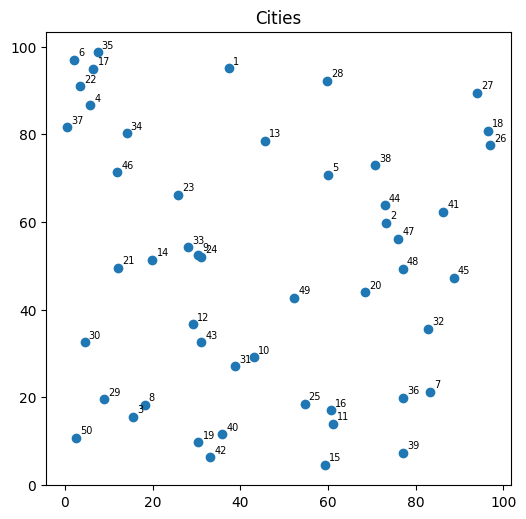

In [3]:
xs, ys = zip(*coords)
plt.figure(figsize=(6, 6))
plt.scatter(xs, ys)
for name, (x, y) in zip(names, coords):
    plt.annotate(name.replace("City_", ""), (x, y), fontsize=7,
                 xytext=(3, 3), textcoords="offset points")
plt.title("Cities")
plt.gca().set_aspect("equal")
plt.show()

## 2. Representation, evaluation and neighbourhoods

The `TSP` class below holds everything the algorithms need:

* **Representation** – a route is a list of city indices, e.g. `[3, 0, 4, 1, 2]`.
* **Evaluation** – `tour_length(route)` sums the distances, using a distance matrix computed once at the start.
* **Neighbourhood** – how a *neighbour* of a route is produced. Two options:
  * **swap** – exchange the positions of two cities (the same operator as swapping letters in the `EAST → EATS` example).
  * **2-opt** – reverse the section of the route between two positions. This removes two edges and reconnects the route the other way, which is very effective at untangling routes that cross themselves.

#### Speeding up evaluation (delta evaluation)
A neighbour only differs from the current route in a few edges, so `delta(route, move)` computes just the **change** in length instead of re-summing all 50 edges. For 2-opt, reversing positions $i..j$ replaces edges $(a,b)$ and $(c,e)$ with $(a,c)$ and $(b,e)$:

$$\Delta = d(a,c) + d(b,e) - d(a,b) - d(c,e)$$

A negative $\Delta$ means the neighbour is shorter (better).

In [4]:
# ---- Parameters -------------------------------------------------------------
NEIGHBOURHOOD = "2opt"  # "2opt" or "swap": the move used by every algorithm in the experiments

In [5]:
class TSP:
    # Cities, distance matrix and neighbourhood operators.
    # A move is a pair of positions (i, j) with i < j.

    def __init__(self, names, coords, neighbourhood="2opt"):
        if neighbourhood not in ("swap", "2opt"):
            raise ValueError("neighbourhood must be 'swap' or '2opt'")
        self.names = names
        self.coords = coords
        self.n = len(coords)
        self.neighbourhood = neighbourhood
        self.dist = [[math.dist(a, b) for b in coords] for a in coords]
        self.evaluations = 0  # counts full + partial (delta) evaluations
        self.t0 = time.perf_counter()

    # ---- book-keeping for experiments ------------------------------------
    def start_clock(self):
        # Reset the evaluation counter and timer at the start of a run
        self.evaluations = 0
        self.t0 = time.perf_counter()

    def snapshot(self, length):
        # One point on a convergence curve: (evaluations, seconds, length)
        return (self.evaluations, time.perf_counter() - self.t0, length)

    # ---- evaluation ------------------------------------------------------
    def tour_length(self, route):
        # Total length of the closed route (k = 0 pairs route[-1] with route[0])
        self.evaluations += 1
        d = self.dist
        return sum(d[route[k - 1]][route[k]] for k in range(len(route)))

    def random_route(self, rng):
        route = list(range(self.n))
        rng.shuffle(route)
        return route

    # ---- neighbourhood ---------------------------------------------------
    def _is_valid(self, i, j):
        # Reversing the whole route gives the same tour, so skip it for 2-opt
        return not (self.neighbourhood == "2opt" and i == 0 and j == self.n - 1)

    def moves(self):
        # Every move in the neighbourhood of a route
        for i in range(self.n - 1):
            for j in range(i + 1, self.n):
                if self._is_valid(i, j):
                    yield (i, j)

    def random_move(self, rng):
        # One random move from the neighbourhood (used by simulated annealing)
        while True:
            i, j = sorted(rng.sample(range(self.n), 2))
            if self._is_valid(i, j):
                return (i, j)

    def apply(self, route, move):
        # Return a NEW route with the move applied
        i, j = move
        new = route[:]
        if self.neighbourhood == "2opt":
            new[i:j + 1] = reversed(new[i:j + 1])
        else:
            new[i], new[j] = new[j], new[i]
        return new

    def delta(self, route, move):
        # Change in route length if `move` were applied (negative = better)
        self.evaluations += 1
        i, j = move
        n, d = self.n, self.dist

        if self.neighbourhood == "2opt":
            a, b = route[i - 1], route[i]
            c, e = route[j], route[(j + 1) % n]
            return d[a][c] + d[b][e] - d[a][b] - d[c][e]

        # swap: edge k joins route[k] and route[k+1]; positions i and j each
        # touch two edges. A set removes duplicates when i and j are adjacent.
        edges = {(i - 1) % n, i, (j - 1) % n, j}

        def cost(r):
            return sum(d[r[k]][r[(k + 1) % n]] for k in edges)

        before = cost(route)
        route[i], route[j] = route[j], route[i]
        after = cost(route)
        route[i], route[j] = route[j], route[i]  # undo
        return after - before

Quick check that the delta evaluation agrees with a full evaluation for both neighbourhoods:

In [6]:
rng = random.Random(0)
for nb in ("2opt", "swap"):
    tsp = TSP(names, coords, nb)
    route = tsp.random_route(rng)
    for move in list(tsp.moves())[:: 97]:
        full = tsp.tour_length(tsp.apply(route, move)) - tsp.tour_length(route)
        assert math.isclose(tsp.delta(route, move), full, abs_tol=1e-9)
    print(f"{nb}: delta evaluation matches full evaluation "
          f"({sum(1 for _ in tsp.moves())} neighbours per route)")

2opt: delta evaluation matches full evaluation (1224 neighbours per route)
swap: delta evaluation matches full evaluation (1225 neighbours per route)


Helper functions used throughout the notebook for plotting routes and convergence:

In [7]:
def plot_route(tsp, route, title, ax=None):
    ax = ax or plt.gca()
    closed = route + route[:1]
    xs = [tsp.coords[c][0] for c in closed]
    ys = [tsp.coords[c][1] for c in closed]
    ax.plot(xs, ys, "o-", markersize=4)
    ax.plot(xs[0], ys[0], "rs", markersize=8, label="Start")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend(loc="upper right")


def plot_convergence(history, title, ax=None):
    ax = ax or plt.gca()
    evals, _, lengths = zip(*history)
    ax.step(evals, lengths, where="post", marker=".")
    ax.set_xlabel("Evaluations")
    ax.set_ylabel("Route length")
    ax.set_title(title)


def show_result(tsp, start, route, length, history, name):
    print(f"{name}: start length {tsp.tour_length(start):.2f} -> final length {length:.2f} "
          f"({len(history) - 1} improvements, {tsp.evaluations:,} evaluations)")
    _, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))
    plot_route(tsp, start, "Random start", ax1)
    plot_route(tsp, route, f"{name} ({length:.2f})", ax2)
    plot_convergence(history, "Convergence", ax3)
    plt.tight_layout()
    plt.show()


# One problem instance and one random starting route shared by the
# single-start methods, so they can be compared fairly.
SEED = 42
tsp = TSP(names, coords, neighbourhood=NEIGHBOURHOOD)
start_route = tsp.random_route(random.Random(SEED))
print(f"Starting route length: {tsp.tour_length(start_route):.2f}")

Starting route length: 2658.99


## 3. Simple hill climbing

**Algorithm**
1. Generate a random initial route and evaluate it.
2. Loop:
   * Look at neighbours **one at a time** (in a random order).
   * As soon as a neighbour is **better**, move to it and start looking again.
   * If no neighbour is better, **stop** – the route is a local optimum.

This is the same rule as the `EAST → EATS` example: *"It only checks its one successor state, and if it finds better than the current state, then it moves to that state."* It is cheap per step, but it takes the first improvement it finds rather than the best one.

**Parameters:** none. This method runs until it reaches a local optimum; the neighbourhood is set by `NEIGHBOURHOOD` in section 2.

In [8]:
def simple_hill_climb(tsp, rng, start=None):
    current = start[:] if start else tsp.random_route(rng)
    length = tsp.tour_length(current)
    history = [tsp.snapshot(length)]

    improved = True
    while improved:
        improved = False
        moves = list(tsp.moves())
        rng.shuffle(moves)
        for move in moves:
            change = tsp.delta(current, move)
            if change < -EPS:
                current = tsp.apply(current, move)
                length += change
                history.append(tsp.snapshot(length))
                improved = True
                break  # move immediately (simple hill climbing)

    return current, length, history

Simple hill climbing: start length 2658.99 -> final length 575.74 (142 improvements, 6,565 evaluations)


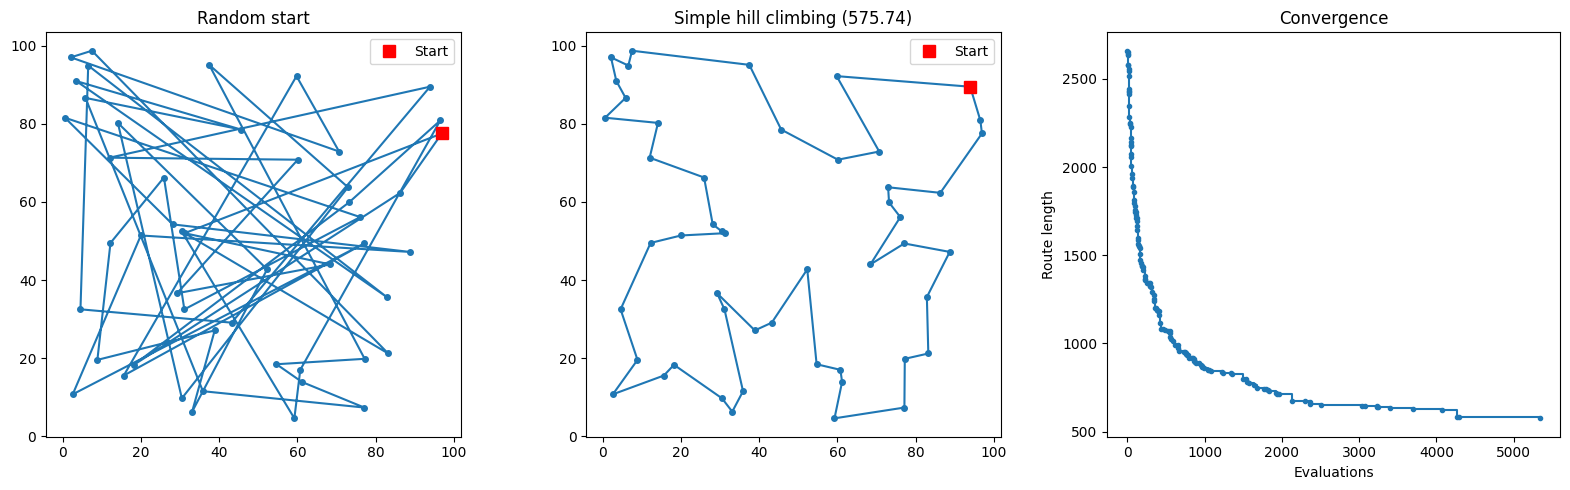

In [9]:
tsp.start_clock()
route, length, history = simple_hill_climb(tsp, random.Random(SEED), start_route)
show_result(tsp, start_route, route, length, history, "Simple hill climbing")

## 4. Steepest-ascent hill climbing

**Algorithm**
1. Generate a random initial route and evaluate it.
2. Loop:
   * Evaluate **every** neighbour of the current route.
   * If the **best** neighbour is better than the current route, move to it.
   * Otherwise **stop** – local optimum.

This matches the 8-bit example in the module notebook (`best = max(neighbours(bits), key=fitness)`). Each step makes the largest possible improvement, but costs a full neighbourhood scan (1,224 neighbours for 50 cities with 2-opt).

**Parameters:** none. This method runs until it reaches a local optimum; the neighbourhood is set by `NEIGHBOURHOOD` in section 2.

In [10]:
def steepest_ascent_hill_climb(tsp, rng, start=None):
    current = start[:] if start else tsp.random_route(rng)
    length = tsp.tour_length(current)
    history = [tsp.snapshot(length)]

    while True:
        best_move, best_change = None, -EPS
        for move in tsp.moves():
            change = tsp.delta(current, move)
            if change < best_change:
                best_move, best_change = move, change

        if best_move is None:  # no neighbour is better -> local optimum
            break
        current = tsp.apply(current, best_move)
        length += best_change
        history.append(tsp.snapshot(length))

    return current, length, history

Steepest ascent: start length 2658.99 -> final length 642.81 (41 improvements, 51,410 evaluations)


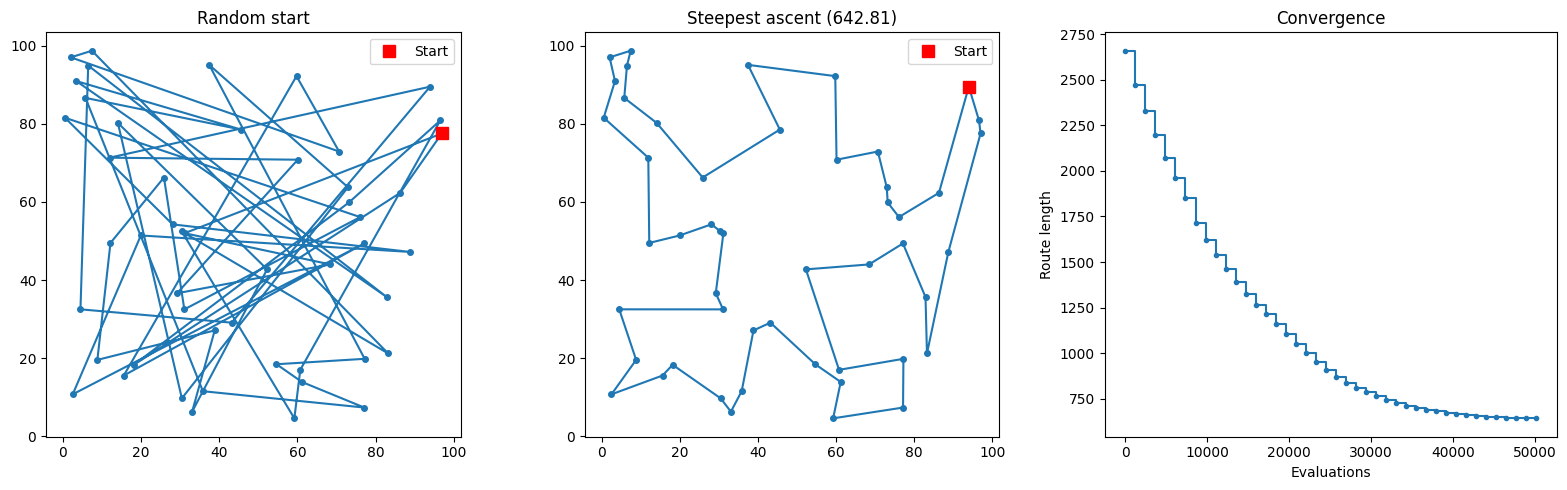

In [11]:
tsp.start_clock()
route, length, history = steepest_ascent_hill_climb(tsp, random.Random(SEED), start_route)
show_result(tsp, start_route, route, length, history, "Steepest ascent")

## 5. Stochastic hill climbing

**Algorithm**
1. Generate a random initial route and evaluate it.
2. Loop:
   * Evaluate every neighbour and collect all the ones that are **better**.
   * Pick **one of them at random** and move to it.
   * If none are better, **stop** – local optimum.

Steepest ascent always takes the biggest improvement, which can lead it greedily into a poor local optimum. Choosing randomly among the improving moves adds variety, so repeated runs explore different paths up the hill.

> *Note:* some textbooks use a different definition – pick a single random neighbour and accept it if it is better (as in the `Hello, World!` example). That version is very close to simple hill climbing with random neighbour order.

**Parameters:** none. This method runs until it reaches a local optimum; the neighbourhood is set by `NEIGHBOURHOOD` in section 2.

In [12]:
def stochastic_hill_climb(tsp, rng, start=None):
    current = start[:] if start else tsp.random_route(rng)
    length = tsp.tour_length(current)
    history = [tsp.snapshot(length)]

    while True:
        improving = []
        for move in tsp.moves():
            change = tsp.delta(current, move)
            if change < -EPS:
                improving.append((move, change))

        if not improving:
            break
        move, change = rng.choice(improving)
        current = tsp.apply(current, move)
        length += change
        history.append(tsp.snapshot(length))

    return current, length, history

Stochastic hill climbing: start length 2658.99 -> final length 582.69 (130 improvements, 160,346 evaluations)


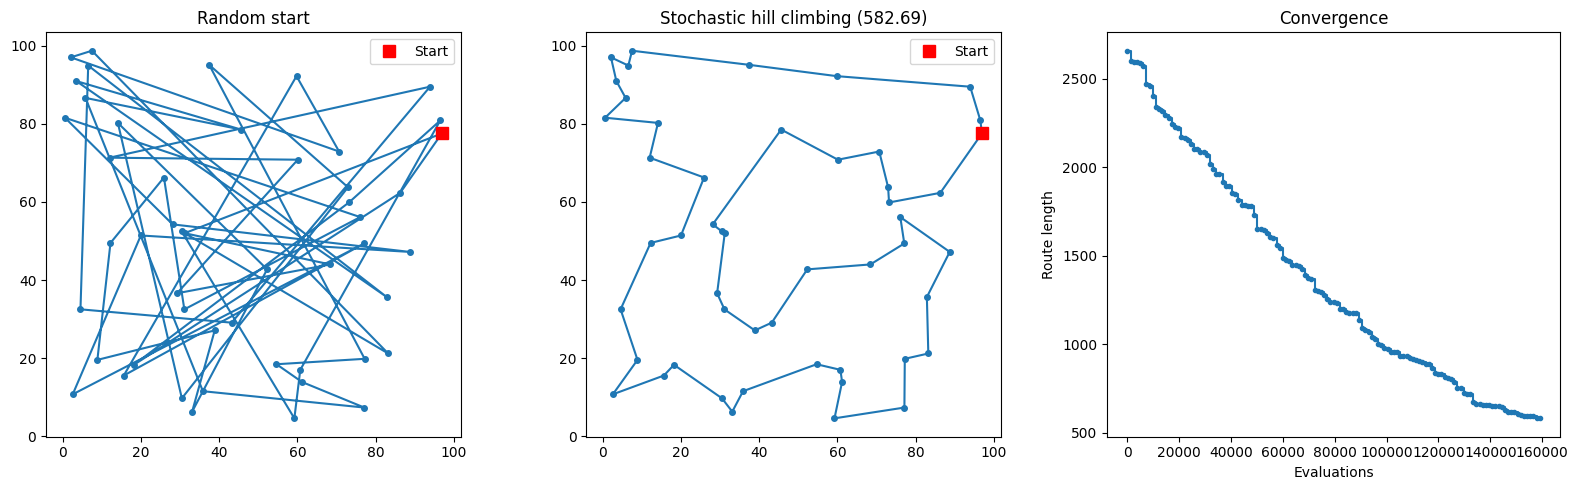

In [13]:
tsp.start_clock()
route, length, history = stochastic_hill_climb(tsp, random.Random(SEED), start_route)
show_result(tsp, start_route, route, length, history, "Stochastic hill climbing")

## 6. Random-restart hill climbing

All three methods above stop at the first **local optimum** they reach, and which one they reach depends heavily on the starting route.

**Algorithm**
1. Repeat `restarts` times:
   * Generate a **new random route**.
   * Run a hill climber (simple or steepest ascent, set by `local_search`) to a local optimum.
2. Return the best local optimum found.

Each restart is independent, so nothing learned in one run is carried over to the next.

In [14]:
# ---- Random-restart parameters (edit here) ----------------------------------
RR_PARAMS = {
    "restarts": 10,              # number of independent hill-climbing runs (search budget)
    "local_search": "steepest",  # hill climber used in each run: "simple" or "steepest" (tuned in 9.3)
}

In [15]:
LOCAL_SEARCHES = {"simple": simple_hill_climb, "steepest": steepest_ascent_hill_climb}


def random_restart_hill_climb(tsp, rng, restarts=10, local_search="steepest", log=None):
    # `log`, if given, collects the local optimum reached by every restart
    local_search = LOCAL_SEARCHES.get(local_search, local_search)
    best_route, best_length = None, math.inf
    history = []

    for _ in range(restarts):
        route, length, inner = local_search(tsp, rng)  # new random start each time
        if log is not None:
            log.append(length)
        for point in inner:  # keep the improvements made inside this climb
            if point[2] < best_length - EPS:
                history.append(point)
        if length < best_length - EPS:
            best_route, best_length = route, length
        history.append(tsp.snapshot(best_length))

    return best_route, best_length, history

Local optimum reached by each restart:
  642.8, 580.1, 627.4, 598.6, 618.3, 615.1, 598.6, 585.1, 578.9, 601.7
Best: 578.94 | worst: 642.81 | evaluations: 565,498


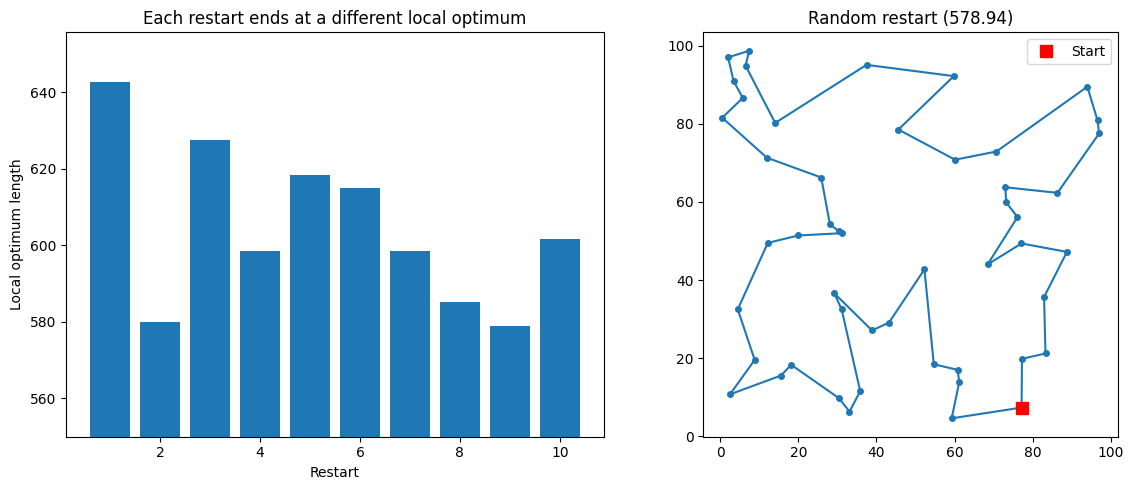

In [16]:
tsp.start_clock()
restart_lengths = []
route, length, history = random_restart_hill_climb(tsp, random.Random(SEED), **RR_PARAMS, log=restart_lengths)

print("Local optimum reached by each restart:")
print("  " + ", ".join(f"{l:.1f}" for l in restart_lengths))
print(f"Best: {length:.2f} | worst: {max(restart_lengths):.2f} | evaluations: {tsp.evaluations:,}")

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.bar(range(1, len(restart_lengths) + 1), restart_lengths)
ax1.set_ylim(min(restart_lengths) * 0.95, max(restart_lengths) * 1.02)
ax1.set_xlabel("Restart")
ax1.set_ylabel("Local optimum length")
ax1.set_title("Each restart ends at a different local optimum")
plot_route(tsp, route, f"Random restart ({length:.2f})", ax2)
plt.tight_layout()
plt.show()

## 7. Iterated local search (ILS)

Random restart throws away everything when it restarts. ILS instead makes a **small jump** from the current local optimum and climbs again, so it keeps most of the good structure already found.

**Algorithm**
1. Generate a random route and run local search to a local optimum.
2. Repeat `iterations` times:
   * **Perturb** the current route (double bridge, below).
   * Run local search from the perturbed route.
   * **Accept** the new local optimum if it is better than the current one.
3. Return the current route.

#### The double-bridge perturbation
Cut the route at three random points into four pieces **A | B | C | D** and reconnect them as **A | C | B | D** (no piece is reversed):

```
before:  0 1 | 2 3 | 4 5 | 6 7      A=[0 1]  B=[2 3]  C=[4 5]  D=[6 7]
after:   0 1 | 4 5 | 2 3 | 6 7
```

Only three connections change (1→2, 3→4, 5→6 become 1→4, 5→2, 3→6), so most of the route is kept. But a single 2-opt or swap move cannot undo it, and undoing it in several moves would mean accepting a worse route on the way, which a hill climber never does. So the local search is pushed into a different *basin of attraction*. (Martin, Otto & Felten, 1991.)

In [17]:
def double_bridge(route, rng):
    n = len(route)
    p1, p2, p3 = sorted(rng.sample(range(1, n), 3))
    return route[:p1] + route[p2:p3] + route[p1:p2] + route[p3:]


# Demonstration on a small route
demo = list(range(8))
print("before:", demo)
print("after: ", double_bridge(demo, random.Random(3)))

before: [0, 1, 2, 3, 4, 5, 6, 7]
after:  [0, 1, 5, 2, 3, 4, 6, 7]


In [18]:
# ---- Iterated local search parameters (edit here) ---------------------------
ILS_PARAMS = {
    "iterations": 100,           # perturb + local search cycles after the first climb (search budget)
    "local_search": "steepest",  # hill climber used after each perturbation: "simple" or "steepest" (tuned in 9.3)
}

In [19]:
def iterated_local_search(tsp, rng, iterations=100, local_search="steepest"):
    local_search = LOCAL_SEARCHES.get(local_search, local_search)
    current, length, history = local_search(tsp, rng)  # history starts with the first climb

    for _ in range(iterations):
        perturbed = double_bridge(current, rng)
        candidate, cand_length, _ = local_search(tsp, rng, start=perturbed)
        if cand_length < length - EPS:  # acceptance criterion: better only
            current, length = candidate, cand_length
        history.append(tsp.snapshot(length))

    return current, length, history

ILS: final length 571.66 (656,165 evaluations)


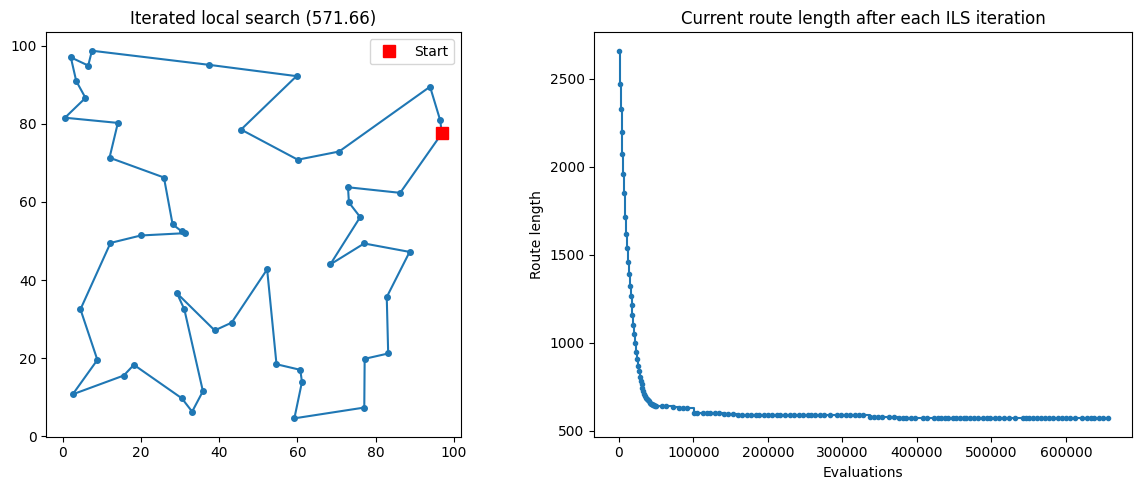

In [20]:
tsp.start_clock()
route, length, history = iterated_local_search(tsp, random.Random(SEED), **ILS_PARAMS)
print(f"ILS: final length {length:.2f} ({tsp.evaluations:,} evaluations)")

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
plot_route(tsp, route, f"Iterated local search ({length:.2f})", ax1)
plot_convergence(history, "Current route length after each ILS iteration", ax2)
plt.tight_layout()
plt.show()

## 8. Simulated annealing (SA)

All the hill climbers above only ever accept **better** routes. Simulated annealing also accepts **worse** routes sometimes, which lets it climb out of a local optimum. The chance of accepting a worse route depends on:
* **how much worse** it is: small steps backwards are accepted more often than large ones;
* the **temperature** $t$, which starts high and falls during the search. Early on the search moves freely; later it behaves more and more like a hill climber.

This is the **Metropolis acceptance criterion** (for minimisation):

$$
P(\text{accept}) = \begin{cases} 1 & \text{if } \Delta < 0 \text{ (better)} \\ \exp(-\Delta / t) & \text{otherwise} \end{cases}
\qquad \Delta = f(\text{candidate}) - f(\text{current})
$$

The implementation below is the teacher's `simulated_annealing()` from the module notebook (*Simulated Annealing Tutorial*), kept line for line where possible, including its **fast annealing schedule** $t = \text{temp}_\text{initial} / (i + 1)$. Only the parts specific to a continuous function have been adapted to the TSP:

| Teacher's version ($f(x) = x^2$) | TSP version |
|---|---|
| Initial point: random value within `bounds` | Random route (`tsp.random_route`) |
| Step: `curr + randn(...) * step_size` (Gaussian step) | A random 2-opt move (`tsp.random_move`): the same neighbourhood as the hill climbers |
| `objective(candidate)` | Delta evaluation: only the change in route length is computed |
| `numpy.random` global seed | A seeded `random.Random` passed in, so runs are reproducible (as for the other algorithms) |
| Initial temperature 10 | Set in `SA_PARAMS` (default 100) and tuned in section 9.3: route-length changes are in the tens of units, whereas $x^2$ on $[-5, 5]$ only ranges from 0 to 25 |
| `scores` list of improvements | `history` list of `tsp.snapshot(...)` entries, for the convergence plots |

One small change in the order of the steps: the teacher checks for a new best **before** the acceptance test. Here it is checked **after** a move is accepted. This gives the same result, because a new best is always an improvement, and improvements are always accepted. It also means a new route is only built when a move is actually accepted.

In [21]:
# ---- Simulated annealing parameters (edit here) -----------------------------
SA_PARAMS = {
    "n_iterations": 100_000,  # number of candidate moves tried (search budget)
    "temp": 100,              # initial temperature of the fast schedule t = temp / (i + 1) (tuned in 9.3)
}

In [22]:
def simulated_annealing(tsp, rng, n_iterations=100_000, temp=100, log=None):
    # `log`, if given, records (iteration, diff, accepted) for every step (used for analysis below)
    # generate an initial point
    best = tsp.random_route(rng)
    # evaluate the initial point
    best_eval = tsp.tour_length(best)
    # current working solution
    curr, curr_eval = best, best_eval
    history = [tsp.snapshot(best_eval)]
    # run the algorithm
    for i in range(n_iterations):
        # take a step: a random 2-opt move instead of a Gaussian step
        move = tsp.random_move(rng)
        # evaluate candidate point: difference between candidate and current route length
        diff = tsp.delta(curr, move)
        candidate_eval = curr_eval + diff
        # calculate temperature for current epoch (fast annealing schedule)
        t = temp / float(i + 1)
        # check if we should keep the new point (Metropolis acceptance criterion);
        # exp() is only computed for worse moves, so it cannot overflow
        accept = diff < 0 or rng.random() < math.exp(-diff / t)
        if log is not None:
            log.append((i, diff, accept))
        if accept:
            # store the new current point
            curr, curr_eval = tsp.apply(curr, move), candidate_eval
            # check for new best solution
            if curr_eval < best_eval - EPS:
                best, best_eval = curr, curr_eval
                # keep track of scores
                history.append(tsp.snapshot(best_eval))
    return best, tsp.tour_length(best), history

Run on the same random starting route as the hill climbers, with the parameters in `SA_PARAMS`:

Simulated annealing: start length 2658.99 -> final length 624.47 (162 improvements, 100,003 evaluations)


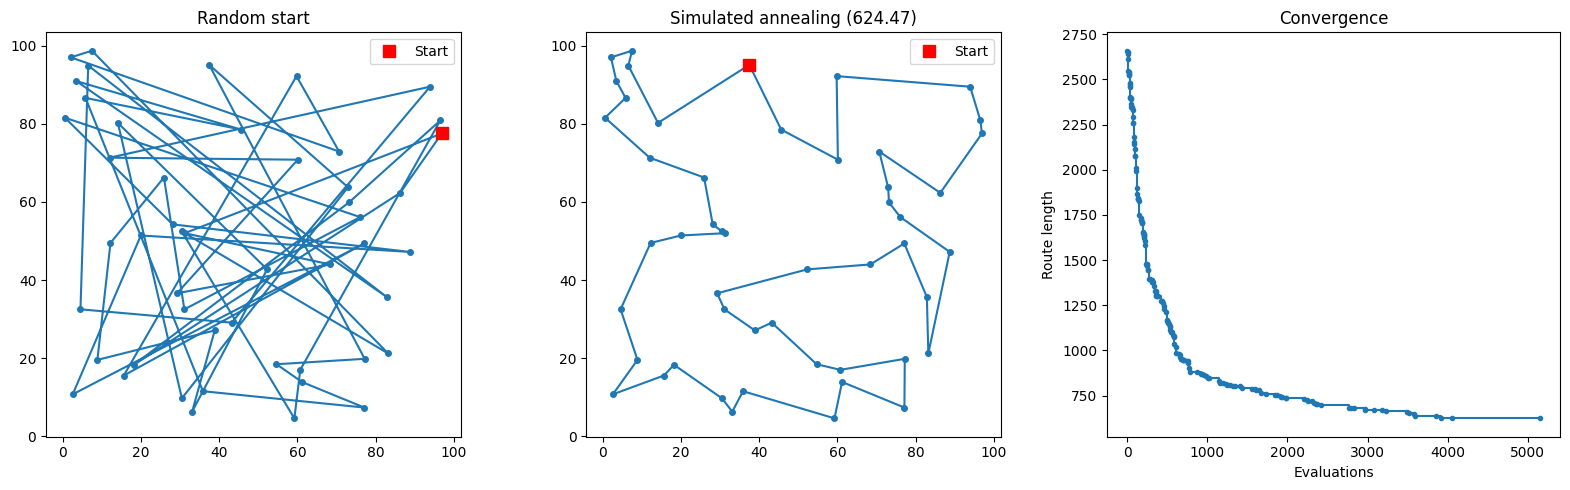

In [23]:
sa_log = []
tsp.start_clock()
route, length, history = simulated_annealing(tsp, random.Random(SEED), **SA_PARAMS, log=sa_log)
show_result(tsp, start_route, route, length, history, "Simulated annealing")
sa_default_length = length

### How the fast annealing schedule behaves on the TSP

As in the teacher's notebook, we can plot the temperature over the iterations and see how often worse routes were actually accepted. The bar chart groups the iterations in powers of ten (1–9, 10–99, 100–999, …) and shows what percentage of the **worse** moves proposed in each group were accepted.

Mean size of a proposed worse move: 85.6


,worse moves proposed,accepted,accepted (%)
iterations,,,
0–9,7,2,28.57
10–99,63,2,3.17
100–999,816,5,0.61
"1,000–9,999",8935,4,0.04
"10,000–99,999",89910,43,0.05


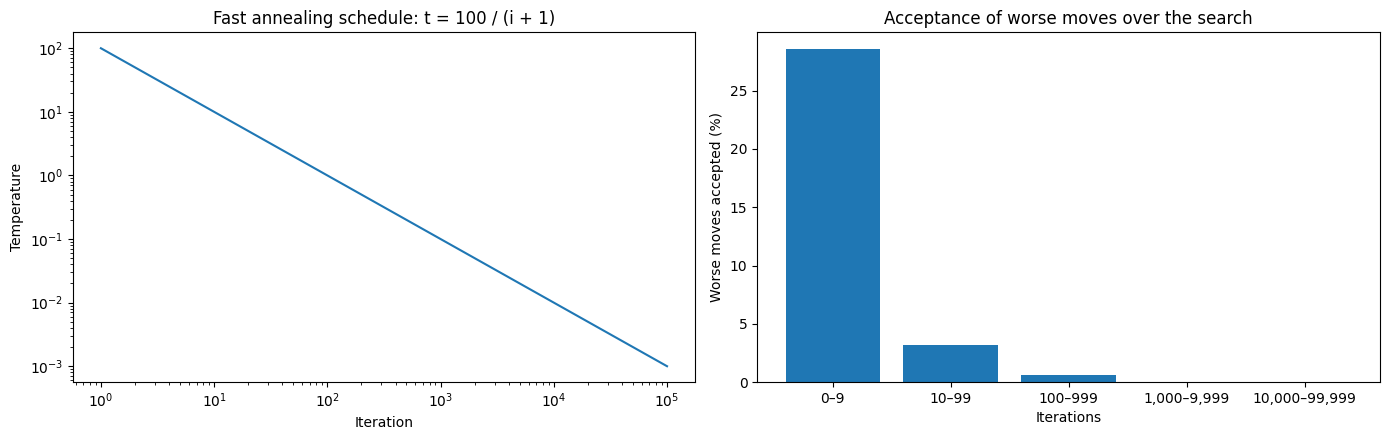

In [24]:
def acceptance_by_phase(sa_log, n_iter):
    # Share of proposed worse moves that were accepted, in phases of 0–9, 10–99, 100–999, ... iterations
    log = np.array(sa_log, dtype=float)  # columns: iteration, diff, accepted
    iters, diffs, accepted = log[:, 0], log[:, 1], log[:, 2].astype(bool)
    worse = diffs > 0
    edges = [0] + [10 ** k for k in range(1, len(str(n_iter))) if 10 ** k < n_iter] + [n_iter]
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = worse & (iters >= lo) & (iters < hi)
        rows.append({"iterations": f"{lo:,}–{hi - 1:,}",
                     "worse moves proposed": int(in_bin.sum()),
                     "accepted": int(accepted[in_bin].sum()),
                     "accepted (%)": round(100 * accepted[in_bin].mean(), 2) if in_bin.any() else 0.0})
    return pd.DataFrame(rows).set_index("iterations"), diffs[worse].mean()


n_iter, temp0 = SA_PARAMS["n_iterations"], SA_PARAMS["temp"]
acceptance_default, mean_worse = acceptance_by_phase(sa_log, n_iter)
print(f"Mean size of a proposed worse move: {mean_worse:.1f}")
display(acceptance_default)

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(np.arange(1, n_iter + 1), temp0 / np.arange(1, n_iter + 1))
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Temperature")
ax1.set_title(f"Fast annealing schedule: t = {temp0} / (i + 1)")
ax2.bar(acceptance_default.index, acceptance_default["accepted (%)"])
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Worse moves accepted (%)")
ax2.set_title("Acceptance of worse moves over the search")
plt.tight_layout()
save_fig("sa_schedule")

The temperature falls very quickly: with the default settings (initial temperature 100, 100,000 iterations) it is below 1 after 100 iterations and 0.001 by the end. A typical worse 2-opt move lengthens the route by tens of units, so once $t$ is small $\exp(-\Delta/t)$ is effectively 0. **After the first few hundred iterations, SA with this schedule accepts almost no worse moves and behaves like a stochastic hill climber** that tries random 2-opt moves. With its default temperature, then, SA is little more than a hill climber. Section 9.3 tunes the initial temperature, which addresses much of this problem.

## 9. Methodology

The algorithms are compared as follows:

1. **Problem instances (9.1):** five sizes, 10–50 cities, taken from the dataset.
2. **Reference solutions (9.2):** the exact optimum for 10 cities, the best known route for the other sizes. Solution quality is measured as the % gap to the reference.
3. **Parameter tuning (9.3):** parameters that change how a method searches are chosen by grid search on *separate tuning runs*. The experiments are therefore not tuned on their own results.
4. **Repeated runs (9.5):** every algorithm is run **20 times** on every instance (seeds 0–19), using the tuned parameters. Each run records the final route length, runtime, number of evaluations and the convergence history.
5. **Descriptive analysis (sections 10–13):** mean and variation (std, 95% confidence interval, median, IQR), runtime, convergence curves and robustness measures.
6. **Statistical hypothesis testing (section 14):** non-parametric tests check which differences are real rather than due to chance, and effect sizes show how large those differences are.

The assessment brief requires each algorithm to be tested on **10, 20, 30, 40 and 50 cities**, comparing for each size:

| Criterion | How it is measured in this notebook |
|---|---|
| Solution quality | Final route length, and % gap to a reference solution (section 10) |
| Runtime performance | Wall-clock time per run, and number of evaluations (section 11) |
| Convergence behaviour | Average best-so-far route length against evaluations and time (section 12) |
| Robustness | Spread over repeated runs: std, coefficient of variation, worst case, hit rate (section 13) |
| Computational scalability | How runtime and evaluations grow with the number of cities, and theoretical complexity (section 11) |
| Statistical significance | Kruskal–Wallis and pairwise Mann–Whitney U tests with Holm correction, plus effect sizes (section 14) |

### 9.1 Problem instances
Each instance uses the **first *n* cities** in `cities 2.csv`. This makes the instances reproducible and nested (the 20-city instance contains the 10-city one), so differences between sizes come from the number of cities rather than from a different random sample. All experiments use the neighbourhood set by `NEIGHBOURHOOD` (2-opt); section 15 justifies this choice.

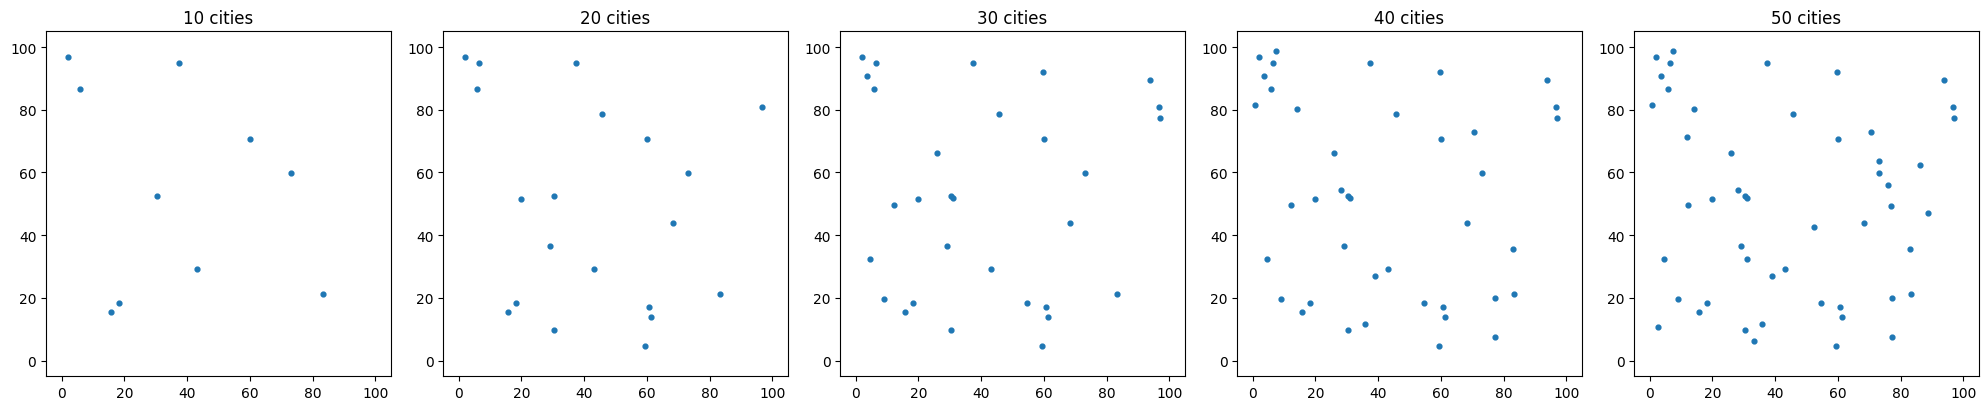

In [25]:
SIZES = [10, 20, 30, 40, 50]
INSTANCES = {n: TSP(names[:n], coords[:n], neighbourhood=NEIGHBOURHOOD) for n in SIZES}

_, axes = plt.subplots(1, len(SIZES), figsize=(20, 4))
for ax, (n, inst) in zip(axes, INSTANCES.items()):
    xs, ys = zip(*inst.coords)
    ax.scatter(xs, ys, s=12)
    ax.set_title(f"{n} cities")
    ax.set_xlim(-5, 105)
    ax.set_ylim(-5, 105)
    ax.set_aspect("equal")
plt.tight_layout()
save_fig("instances")

### 9.2 Reference solutions
To judge solution quality we need something to compare against.

* For **10 cities** the true optimum can be found by **brute force**: fix the first city and try every ordering of the other nine, skipping mirror images ($9!/2 = 181{,}440$ routes).
* For **20–50 cities** brute force is impossible ($19!/2 \approx 6 \times 10^{16}$ routes for 20 cities), so the reference is the **best route found by any run of any algorithm** ("best known").

Quality is then reported as the **percentage gap**: $\text{gap} = 100 \times (L - L_{\text{ref}}) / L_{\text{ref}}$, so 0% means the run matched the reference.

In [26]:
def brute_force_optimum(tsp):
    best_route, best_length = None, math.inf
    for perm in itertools.permutations(range(1, tsp.n)):
        if perm[0] > perm[-1]:  # skip the mirror image of a route already tried
            continue
        route = [0, *perm]
        length = tsp.tour_length(route)
        if length < best_length:
            best_route, best_length = route, length
    return best_route, best_length


t0 = time.perf_counter()
optimal_route_10, optimal_length_10 = brute_force_optimum(INSTANCES[10])
print(f"Optimal 10-city route length: {optimal_length_10:.2f} "
      f"(brute force took {time.perf_counter() - t0:.1f} s)")

Optimal 10-city route length: 290.31 (brute force took 0.2 s)


### 9.3 Parameter tuning

Simple, steepest-ascent and stochastic hill climbing have no parameters: each runs until it reaches a local optimum. The defaults for the other methods are in the parameter cells above their implementations (`RR_PARAMS`, `ILS_PARAMS`, `SA_PARAMS`).

**What is tuned.** Parameters that only set the **search budget** (number of restarts, ILS iterations, SA iterations) are *not* tuned. More budget can only help, so tuning them would simply pick the largest value tried. They are kept at the defaults so the methods have broadly comparable costs. The parameters that change **how** the search behaves are tuned:

| Algorithm | Parameter | Values tried |
|---|---|---|
| Random restart | `local_search`: hill climber used in each restart | simple, steepest |
| Iterated local search | `local_search`: hill climber used after each perturbation | simple, steepest |
| Simulated annealing | `temp`: initial temperature | 1, 10, 100, …, 1,000,000 (powers of 10) |

**Procedure.**
* **Grid search:** every value in `TUNING_GRIDS` is run 10 times on the 50-city instance, the largest and hardest one.
* **Separate seeds:** tuning uses seeds **1000–1009**, separate from the seeds 0–19 used in the experiments, so parameters are not chosen on the same runs they are judged on.
* **Selection:** the setting with the **lowest mean route length** is chosen. If several settings are within 0.1% of the best mean, the fastest of them is chosen instead, since the extra time would buy no real improvement.
* **Saving:** the chosen values are saved to `results/best_params.json` and used in every experiment below.

To tune more parameters or values, edit `TUNING_GRIDS`.

In [27]:
TUNING_SIZE = 50
TUNING_SEEDS = range(1000, 1010)  # kept separate from the experiment seeds (0–19)
TUNING_GRIDS = {
    "Random restart":        {"local_search": ["simple", "steepest"]},
    "Iterated local search": {"local_search": ["simple", "steepest"]},
    "Simulated annealing":   {"temp": [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]},
}
TUNABLE = {  # algorithm -> (function, default parameters)
    "Random restart":        (random_restart_hill_climb, RR_PARAMS),
    "Iterated local search": (iterated_local_search, ILS_PARAMS),
    "Simulated annealing":   (simulated_annealing, SA_PARAMS),
}


def tune(grids, instance, seeds, tolerance=0.001):
    rows, settings = [], {}
    for name, grid in grids.items():
        function, defaults = TUNABLE[name]
        for values in itertools.product(*grid.values()):
            setting = dict(zip(grid, values))
            label = ", ".join(f"{k}={v}" for k, v in setting.items())
            settings[(name, label)] = setting
            for seed in seeds:
                instance.start_clock()
                _, length, _ = function(instance, random.Random(seed), **{**defaults, **setting})
                rows.append({"algorithm": name, "setting": label, "seed": seed, "length": length,
                             "runtime": time.perf_counter() - instance.t0})

    runs = pd.DataFrame(rows)
    table = runs.groupby(["algorithm", "setting"], sort=False).agg(
        mean_length=("length", "mean"), std_length=("length", "std"),
        mean_runtime_ms=("runtime", lambda r: 1000 * r.mean()))

    tuned = {}
    for name in grids:
        t = table.loc[name]
        near_best = t[t["mean_length"] <= t["mean_length"].min() * (1 + tolerance)]
        chosen = near_best["mean_runtime_ms"].idxmin()
        tuned[name] = {**TUNABLE[name][1], **settings[(name, chosen)]}
    return runs, table, tuned


t0 = time.perf_counter()
tuning_runs, tuning_table, TUNED_PARAMS = tune(TUNING_GRIDS, INSTANCES[TUNING_SIZE], TUNING_SEEDS)
print(f"Tuning: {len(tuning_runs)} runs in {time.perf_counter() - t0:.1f} s\n")

tuning_runs.to_csv(RESULTS_DIR / "tuning_runs.csv", index=False)
with open(RESULTS_DIR / "best_params.json", "w") as f:
    json.dump(TUNED_PARAMS, f, indent=2)

print("Selected parameters (saved to results/best_params.json):")
for name, params in TUNED_PARAMS.items():
    print(f"  {name:<22} {params}")
tuning_table.round(2)

Tuning: 110 runs in 28.7 s

Selected parameters (saved to results/best_params.json):
  Random restart         {'restarts': 10, 'local_search': 'steepest'}
  Iterated local search  {'iterations': 100, 'local_search': 'simple'}
  Simulated annealing    {'n_iterations': 100000, 'temp': 100000}


mean_length  std_length  \
algorithm             setting                                          
Random restart        local_search=simple         578.44        6.71   
                      local_search=steepest       573.15        6.63   
Iterated local search local_search=simple         560.18        1.00   
                      local_search=steepest       566.24        7.38   
Simulated annealing   temp=1                      600.93       11.93   
                      temp=10                     594.95       19.31   
                      temp=100                    603.02       19.39   
                      temp=1000                   597.76       15.93   
                      temp=10000                  584.38       12.98   
                      temp=100000                 571.88        5.42   
                      temp=1000000                791.79       34.49   

                                             mean_runtime_ms  
algorithm             setting                                 
Random restart        local_search=simple             401.36  
                      local_search=steepest           185.39  
Iterated local search local_search=simple             562.36  
                      local_search=steepest           209.83  
Simulated annealing   temp=1                          213.53  
                      temp=10                         205.62  
                      temp=100                        206.20  
                      temp=1000                       209.10  
                      temp=10000                      226.27  
                      temp=100000                     220.12  
                      temp=1000000                    232.54

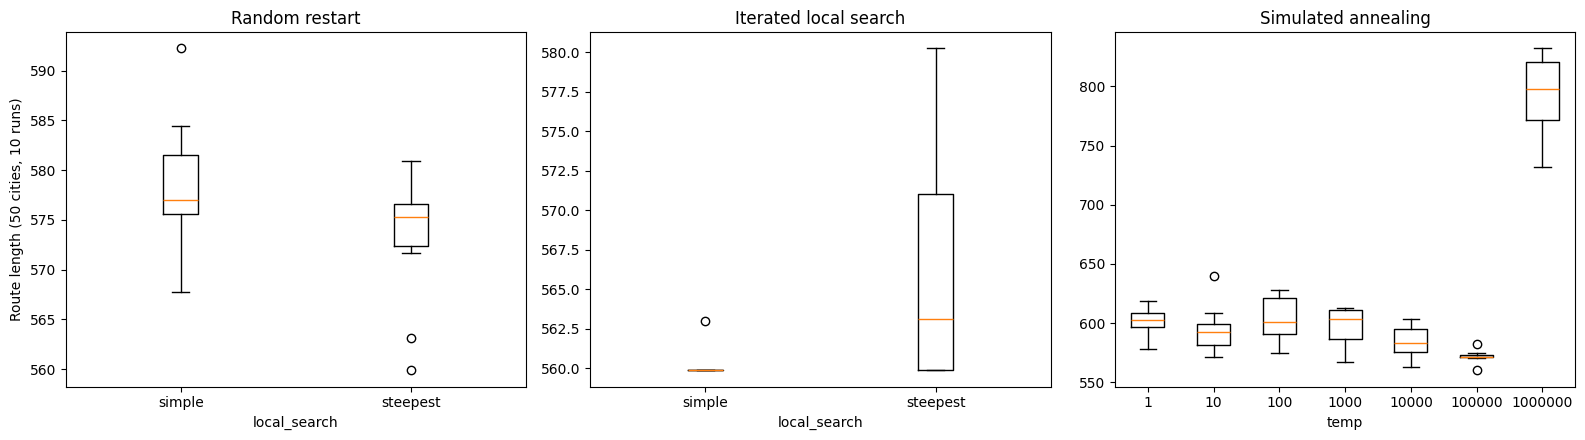

In [28]:
_, axes = plt.subplots(1, len(TUNING_GRIDS), figsize=(16, 4.5))
for ax, name in zip(axes, TUNING_GRIDS):
    sub = tuning_runs[tuning_runs["algorithm"] == name]
    labels = list(dict.fromkeys(sub["setting"]))
    ax.boxplot([sub[sub["setting"] == label]["length"] for label in labels])
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels([label.split("=")[1] for label in labels])
    ax.set_xlabel(", ".join(TUNING_GRIDS[name]))
    ax.set_title(name)
axes[0].set_ylabel(f"Route length ({TUNING_SIZE} cities, {len(TUNING_SEEDS)} runs)")
plt.tight_layout()
save_fig("tuning")

**Tuning results** (10 runs on 50 cities, seeds 1000–1009; route lengths are exact, runtimes vary slightly between executions):

* **Random restart → `steepest`.** Steepest ascent inside each restart gives shorter routes (mean 573.2 vs 578.4) *and* runs about twice as fast as simple hill climbing.
* **Iterated local search → `simple`.** Simple (first-improvement) hill climbing gives clearly shorter and far more consistent routes (mean 560.2, std 1.0, vs 566.2, std 7.4 with steepest ascent), although each run takes roughly 2.5–3× longer. A likely explanation: simple hill climbing takes random, smaller steps, so the climb after each perturbation explores more varied routes. Steepest ascent always takes the same greedy step from a given route, so it is more likely to fall straight back into the local optimum it was kicked out of.
* **Simulated annealing → `temp` = 100,000.** The initial temperature has a large effect:
  * every value from 1 to 1,000 gives poor results (mean 595–603);
  * 10,000 is better (584.4) and **100,000 is best (571.9)**;
  * at 1,000,000 the search is still too hot at the end of its 100,000 iterations ($t = 10$). It keeps accepting worse routes and finishes far from any optimum (791.8).

  The default of 100, chosen by analogy with the teacher's example, is far too low for this problem.

Same starting route (seed 42, 50 cities):
  default temp =       100: final length 624.47
  tuned   temp =   100,000: final length 571.66


,default: accepted (%),tuned: accepted (%)
iterations,,
0–9,28.57,100.00
10–99,3.17,97.96
100–999,0.61,85.33
"1,000–9,999",0.04,20.87
"10,000–99,999",0.05,0.86


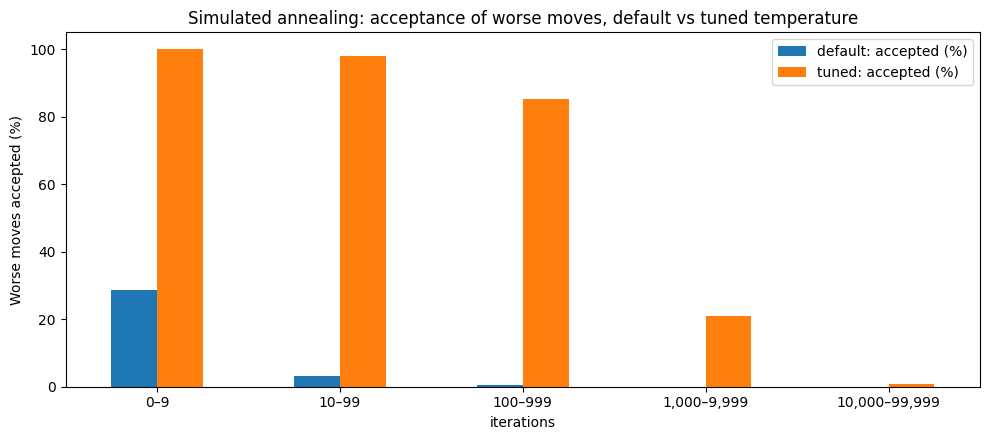

In [29]:
tuned_sa = TUNED_PARAMS["Simulated annealing"]
tuned_log = []
tsp.start_clock()
_, sa_tuned_length, _ = simulated_annealing(tsp, random.Random(SEED), **tuned_sa, log=tuned_log)
acceptance_tuned, _ = acceptance_by_phase(tuned_log, tuned_sa["n_iterations"])

print(f"Same starting route (seed {SEED}, 50 cities):")
print(f"  default temp = {SA_PARAMS['temp']:>9,}: final length {sa_default_length:.2f}")
print(f"  tuned   temp = {tuned_sa['temp']:>9,}: final length {sa_tuned_length:.2f}")
comparison = pd.DataFrame({"default: accepted (%)": acceptance_default["accepted (%)"],
                           "tuned: accepted (%)": acceptance_tuned["accepted (%)"]})
display(comparison)

ax = comparison.plot.bar(figsize=(10, 4.5), rot=0)
ax.set_ylabel("Worse moves accepted (%)")
ax.set_title("Simulated annealing: acceptance of worse moves, default vs tuned temperature")
plt.tight_layout()
save_fig("sa_default_vs_tuned")

**Effect of the tuned temperature.** Both runs use the same fast schedule $t = \text{temp}/(i+1)$ from the teacher's implementation; only the starting temperature differs.
* **Default (100):** the search stops accepting worse moves almost immediately: under 1% from iteration 100 onwards. It reaches a local optimum like a hill climber (624.47 on this starting route).
* **Tuned (100,000):** the temperature stays above the typical size of a worse move (≈ 86) for the first ~1,000 iterations. During that time SA accepts 85–100% of worse moves and **explores freely**. It then cools gradually: 21% acceptance over iterations 1,000–9,999, under 1% after that, when it **climbs** to a good optimum (571.66 on the same starting route).

Raising the temperature therefore moves the switch from exploring to climbing from the first ~100 iterations to roughly the first 1,000–10,000. Because the fast schedule falls by a factor of 10 with every tenfold increase in iterations, the last 90% of the budget is still spent almost entirely on hill climbing.

### 9.4 Algorithms under test
Every algorithm is called through the same interface so the experiment code does not need to know how it works:

```python
route, length, history = algorithm(tsp, rng)
```

* `tsp` – the problem instance. Evaluate routes with `tsp.tour_length(route)` (or `tsp.delta(...)`) so evaluations are counted.
* `rng` – a seeded `random.Random`; use it for **all** random choices so every run is reproducible.
* `route, length` – the best route found and its length.
* `history` – a list of `tsp.snapshot(length)` entries, appended whenever the best length improves. These are used for the convergence plots.

**To add another algorithm**, write a function with this interface and add it to `ALGORITHMS` below. It is then included in every table and plot.

> **Note on fairness:** evaluation counts are a fair cost measure *between the hill climbers and simulated annealing*, which all use the same move evaluation. An algorithm that evaluates whole routes (e.g. a population-based method) does more work per evaluation, so **runtime** is the fairer measure when comparing different kinds of algorithm.

In [30]:
ALGORITHMS = {
    "Simple":                lambda tsp, rng: simple_hill_climb(tsp, rng),
    "Steepest ascent":       lambda tsp, rng: steepest_ascent_hill_climb(tsp, rng),
    "Stochastic":            lambda tsp, rng: stochastic_hill_climb(tsp, rng),
    "Random restart":        lambda tsp, rng: random_restart_hill_climb(tsp, rng, **TUNED_PARAMS["Random restart"]),
    "Iterated local search": lambda tsp, rng: iterated_local_search(tsp, rng, **TUNED_PARAMS["Iterated local search"]),
}
HILL_CLIMBERS = list(ALGORITHMS)

ALGORITHMS["Simulated annealing"] = lambda tsp, rng: simulated_annealing(tsp, rng, **TUNED_PARAMS["Simulated annealing"])
NEIGHBOURHOOD_METHODS = HILL_CLIMBERS + ["Simulated annealing"]  # methods that use the swap / 2-opt moves

# Add the other algorithms here once they are implemented, for example:
# ALGORITHMS["My algorithm"] = lambda tsp, rng: my_algorithm(tsp, rng, some_parameter=...)

### 9.5 Running the experiments
Each algorithm is run **20 times** on each instance, with seeds 0–19, using the tuned parameters from 9.3. Using the same seed for every algorithm means the single-start hill climbers all begin from the same random route in a given run, so differences come from the search strategy rather than the starting point.

Every returned route is checked: it must visit each city exactly once, and its reported length must match a full re-evaluation.

In [31]:
RUNS = 20


def run_experiments(algorithms, instances, runs):
    rows, histories, routes = [], {}, {}
    for n, tsp in instances.items():
        t_size = time.perf_counter()
        for name, algorithm in algorithms.items():
            for seed in range(runs):
                tsp.start_clock()
                route, length, history = algorithm(tsp, random.Random(seed))
                runtime = time.perf_counter() - tsp.t0
                evaluations = tsp.evaluations

                assert sorted(route) == list(range(tsp.n)), f"{name}: invalid route"
                assert math.isclose(length, tsp.tour_length(route), rel_tol=1e-9), \
                    f"{name}: reported length does not match the route"

                rows.append({"algorithm": name, "n": n, "seed": seed, "length": length,
                             "runtime": runtime, "evaluations": evaluations})
                histories[(name, n, seed)] = history
                routes[(name, n, seed)] = route
        print(f"{n:>2} cities: done in {time.perf_counter() - t_size:.1f} s")
    return pd.DataFrame(rows), histories, routes


t0 = time.perf_counter()
df, histories, routes = run_experiments(ALGORITHMS, INSTANCES, RUNS)
print(f"Total: {len(df)} runs in {time.perf_counter() - t0:.1f} s")

# Reference solution for each size (exact optimum for 10 cities)
reference = df.groupby("n")["length"].min().to_dict()
reference[10] = optimal_length_10
df["gap_%"] = 100 * (df["length"] - df["n"].map(reference)) / df["n"].map(reference)
df["hit"] = df["gap_%"] <= 1.0  # within 1% of the reference

ALGO_ORDER = list(ALGORITHMS)
df["algorithm"] = pd.Categorical(df["algorithm"], categories=ALGO_ORDER, ordered=True)
df.to_csv(RESULTS_DIR / "runs.csv", index=False)
print("Reference lengths:", {n: round(v, 2) for n, v in reference.items()})

10 cities: done in 4.4 s
20 cities: done in 5.6 s
30 cities: done in 8.6 s
40 cities: done in 13.7 s
50 cities: done in 21.8 s
Total: 600 runs in 54.2 s
Reference lengths: {10: 290.31, 20: 386.43, 30: 451.77, 40: 489.73, 50: 559.86}


## 10. Solution quality

Mean ± standard deviation of the final route length over the 20 runs, for each algorithm and problem size:

In [32]:
def pivot(values, aggfunc="mean"):
    return df.pivot_table(index="algorithm", columns="n", values=values,
                          aggfunc=aggfunc, observed=True)


mean_len, std_len = pivot("length"), pivot("length", "std")
quality_table = mean_len.round(1).astype(str) + " ± " + std_len.round(1).astype(str)
quality_table.columns = [f"{n} cities" for n in quality_table.columns]
quality_table

,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,290.3 ± 0.0,392.7 ± 19.0,476.7 ± 18.0,533.8 ± 28.3,604.6 ± 21.0
Steepest ascent,290.3 ± 0.0,386.5 ± 0.1,466.6 ± 18.0,533.3 ± 22.0,594.2 ± 18.0
Stochastic,290.3 ± 0.0,392.6 ± 18.7,478.4 ± 23.6,529.1 ± 30.9,600.4 ± 20.9
Random restart,290.3 ± 0.0,386.4 ± 0.0,452.8 ± 2.1,492.6 ± 3.6,571.2 ± 7.0
Iterated local search,290.3 ± 0.0,386.4 ± 0.0,451.8 ± 0.0,489.8 ± 0.1,561.0 ± 3.5
Simulated annealing,290.3 ± 0.0,386.4 ± 0.0,452.7 ± 1.1,491.1 ± 1.4,571.2 ± 7.3


### Mean performance and variation

For each size: the mean, its **95% confidence interval** (the range that would contain the true mean in 95% of repeated experiments), the standard deviation, and the **median and interquartile range (IQR)**. The median and IQR are less affected by a few unusually bad runs than the mean and std, which suits skewed results like these.

In [33]:
def ci95_halfwidth(x):
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))


g = df.groupby(["n", "algorithm"], observed=True)["length"]
variation = pd.DataFrame({
    "mean": g.mean(),
    "95% CI ±": g.apply(ci95_halfwidth),
    "std": g.std(),
    "median": g.median(),
    "IQR": g.quantile(0.75) - g.quantile(0.25),
    "min": g.min(),
    "max": g.max(),
}).round(2)
variation.to_csv(RESULTS_DIR / "variation.csv")
variation

mean  95% CI ±    std  median    IQR     min  \
n  algorithm                                                               
10 Simple                 290.31      0.00   0.00  290.31   0.00  290.31   
   Steepest ascent        290.31      0.00   0.00  290.31   0.00  290.31   
   Stochastic             290.31      0.00   0.00  290.31   0.00  290.31   
   Random restart         290.31      0.00   0.00  290.31   0.00  290.31   
   Iterated local search  290.31      0.00   0.00  290.31   0.00  290.31   
   Simulated annealing    290.31      0.00   0.00  290.31   0.00  290.31   
20 Simple                 392.67      8.90  19.01  386.53   0.20  386.43   
   Steepest ascent        386.53      0.05   0.10  386.53   0.20  386.43   
   Stochastic             392.57      8.73  18.65  386.53   0.20  386.43   
   Random restart         386.43      0.00   0.00  386.43   0.00  386.43   
   Iterated local search  386.43      0.00   0.00  386.43   0.00  386.43   
   Simulated annealing    386.43      0.00   0.00  386.43   0.00  386.43   
30 Simple                 476.74      8.43  18.02  473.99  15.89  451.77   
   Steepest ascent        466.63      8.42  18.00  459.89  17.25  451.77   
   Stochastic             478.43     11.02  23.56  478.54  34.66  451.77   
   Random restart         452.76      0.99   2.12  451.77   0.53  451.77   
   Iterated local search  451.77      0.00   0.00  451.77   0.00  451.77   
   Simulated annealing    452.72      0.51   1.08  451.78   2.14  451.77   
40 Simple                 533.81     13.25  28.32  537.93  51.92  492.29   
   Steepest ascent        533.26     10.30  22.01  537.70  26.99  490.39   
   Stochastic             529.11     14.47  30.91  526.46  51.38  491.63   
   Random restart         492.57      1.66   3.55  491.63   3.09  489.73   
   Iterated local search  489.76      0.07   0.15  489.73   0.00  489.73   
   Simulated annealing    491.06      0.66   1.40  491.63   1.90  489.73   
50 Simple                 604.61      9.83  21.01  599.18  29.22  571.66   
   Steepest ascent        594.23      8.43  18.02  592.92  16.19  568.11   
   Stochastic             600.36      9.78  20.89  600.78  32.23  559.86   
   Random restart         571.23      3.27   6.99  571.34   8.15  559.86   
   Iterated local search  561.01      1.65   3.53  559.86   0.00  559.86   
   Simulated annealing    571.22      3.42   7.30  571.83  12.99  559.86   

                             max  
n  algorithm                      
10 Simple                 290.31  
   Steepest ascent        290.31  
   Stochastic             290.31  
   Random restart         290.31  
   Iterated local search  290.31  
   Simulated annealing    290.31  
20 Simple                 453.27  
   Steepest ascent        386.63  
   Stochastic             450.07  
   Random restart         386.43  
   Iterated local search  386.43  
   Simulated annealing    386.43  
30 Simple                 517.43  
   Steepest ascent        510.12  
   Stochastic             528.03  
   Random restart         458.53  
   Iterated local search  451.77  
   Simulated annealing    453.90  
40 Simple                 579.38  
   Steepest ascent        574.25  
   Stochastic             589.20  
   Random restart         502.66  
   Iterated local search  490.39  
   Simulated annealing    495.18  
50 Simple                 646.28  
   Steepest ascent        642.90  
   Stochastic             643.03  
   Random restart         585.00  
   Iterated local search  571.66  
   Simulated annealing    582.26

Mean % gap to the reference solution (0 = matched the optimum / best known), and the best single run:

In [34]:
gap_table = pivot("gap_%").round(2)
gap_table.columns = [f"{n} cities" for n in gap_table.columns]
print("Mean gap to reference (%)")
display(gap_table)

best_table = pivot("length", "min").round(2)
best_table.loc["Reference"] = [reference[n] for n in best_table.columns]
best_table.columns = [f"{n} cities" for n in best_table.columns]
print("Best route length in 20 runs (reference row: optimum for 10 cities, best known otherwise)")
display(best_table.round(2))

Mean gap to reference (%)


,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,0.0,1.61,5.53,9.00,7.99
Steepest ascent,0.0,0.03,3.29,8.89,6.14
Stochastic,0.0,1.59,5.90,8.04,7.23
Random restart,0.0,0.00,0.22,0.58,2.03
Iterated local search,0.0,0.00,0.00,0.01,0.21
Simulated annealing,0.0,0.00,0.21,0.27,2.03


Best route length in 20 runs (reference row: optimum for 10 cities, best known otherwise)


,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,290.31,386.43,451.77,492.29,571.66
Steepest ascent,290.31,386.43,451.77,490.39,568.11
Stochastic,290.31,386.43,451.77,491.63,559.86
Random restart,290.31,386.43,451.77,489.73,559.86
Iterated local search,290.31,386.43,451.77,489.73,559.86
Simulated annealing,290.31,386.43,451.77,489.73,559.86
Reference,290.31,386.43,451.77,489.73,559.86


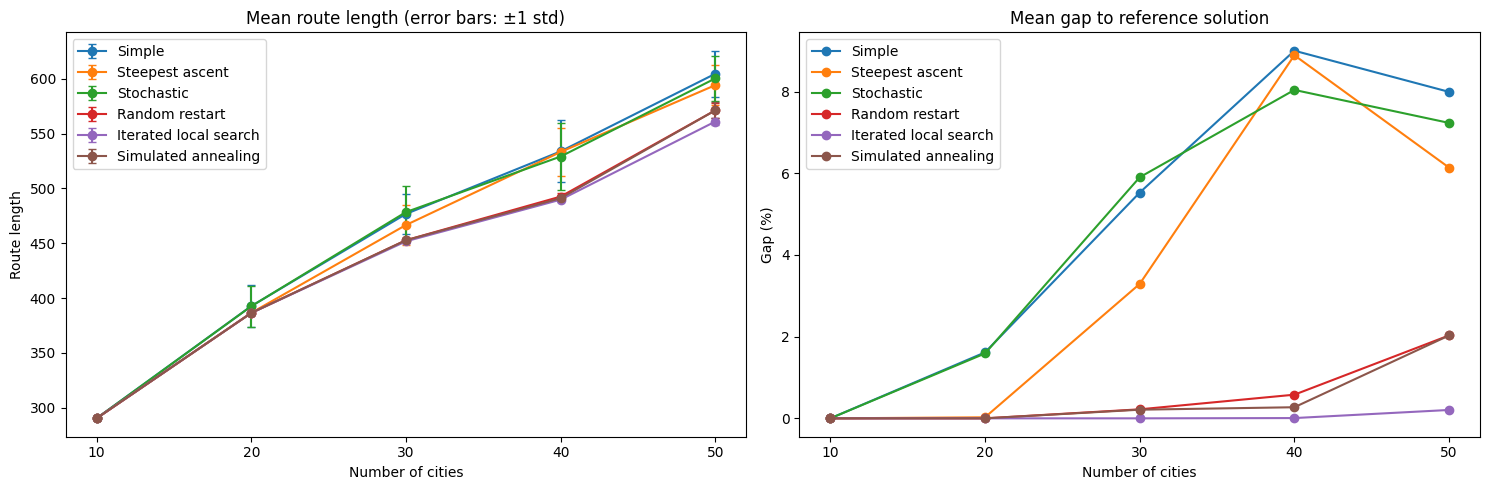

In [35]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ALGO_ORDER:
    sub = df[df["algorithm"] == name].groupby("n")
    ax1.errorbar(SIZES, sub["length"].mean(), yerr=sub["length"].std(),
                 marker="o", capsize=3, label=name)
    ax2.plot(SIZES, sub["gap_%"].mean(), marker="o", label=name)
ax1.set_title("Mean route length (error bars: ±1 std)")
ax1.set_ylabel("Route length")
ax2.set_title("Mean gap to reference solution")
ax2.set_ylabel("Gap (%)")
for ax in (ax1, ax2):
    ax.set_xlabel("Number of cities")
    ax.set_xticks(SIZES)
    ax.legend()
plt.tight_layout()
save_fig("solution_quality")

## 11. Runtime performance and scalability

Mean runtime per run (milliseconds) and mean number of evaluations:

In [36]:
runtime_table = (pivot("runtime") * 1000).round(1)
runtime_table.columns = [f"{n} cities" for n in runtime_table.columns]
print("Mean runtime per run (ms)")
display(runtime_table)

evals_table = pivot("evaluations").round(0).astype(int)
evals_table.columns = [f"{n} cities" for n in evals_table.columns]
print("Mean evaluations per run")
display(evals_table)

Mean runtime per run (ms)


,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,0.2,1.6,6.6,21.9,41.4
Steepest ascent,0.1,0.9,4.0,9.6,18.7
Stochastic,0.2,2.4,10.1,25.9,55.8
Random restart,1.1,11.0,40.8,91.9,190.5
Iterated local search,11.1,57.9,154.6,322.1,572.5
Simulated annealing,207.6,208.1,214.4,215.5,213.3


Mean evaluations per run


,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,122,699,1810,3448,6380
Steepest ascent,300,3072,11697,27928,58447
Stochastic,485,6937,27169,76226,162426
Random restart,3037,31356,113371,283371,580737
Iterated local search,10070,52451,123618,237107,387561
Simulated annealing,100002,100002,100002,100002,100002


To measure **scalability**, we fit $\text{runtime} \approx c \cdot n^k$ by linear regression on a log–log scale. The exponent $k$ says how fast the cost grows: $k = 2$ means doubling the number of cities makes a run about 4× slower, $k = 3$ about 8× slower.

#### Theoretical computational complexity
Let $N = n(n-1)/2 - 1 = O(n^2)$ be the size of the 2-opt neighbourhood. Evaluating one move with delta evaluation costs $O(1)$; applying an accepted move costs $O(n)$, since the route is copied and a segment reversed. Every method stores the $O(n^2)$ distance matrix.

| Algorithm | Cost of one step | Number of steps | Expected total cost |
|---|---|---|---|
| Simple | Up to $N$ move evaluations (stops at the first improvement), plus $O(N)$ to build and shuffle the move list | Grows with $n$ | Between $O(n^2)$ and $O(n^3)$ |
| Steepest ascent | Exactly $N = O(n^2)$ evaluations | Grows roughly linearly with $n$ | ≈ $O(n^3)$ |
| Stochastic | $N = O(n^2)$ evaluations, plus storing all improving moves | More steps than steepest (smaller improvements) | Above $O(n^3)$ |
| Random restart | One full hill climb per restart | `restarts` (fixed) | `restarts` × hill-climb cost |
| ILS | One (usually short) hill climb per iteration | `iterations` (fixed) | `iterations` × short-climb cost |
| Simulated annealing | $O(1)$ per iteration, plus $O(n)$ when a move is accepted | `n_iterations` (fixed) | ≈ $O(\text{n\_iterations})$: almost independent of $n$ |

The empirical exponents below test these expectations.

In [37]:
scaling = {}
for name in ALGO_ORDER:
    sub = df[df["algorithm"] == name].groupby("n")
    k_time = np.polyfit(np.log(SIZES), np.log(sub["runtime"].mean()), 1)[0]
    k_eval = np.polyfit(np.log(SIZES), np.log(sub["evaluations"].mean()), 1)[0]
    scaling[name] = {"runtime exponent k": round(k_time, 2),
                     "evaluations exponent k": round(k_eval, 2),
                     "runtime 50 / runtime 10": round(sub["runtime"].mean()[50] / sub["runtime"].mean()[10], 1)}
pd.DataFrame(scaling).T

,runtime exponent k,evaluations exponent k,runtime 50 / runtime 10
Simple,3.42,2.43,227.3
Steepest ascent,3.23,3.27,173.0
Stochastic,3.55,3.60,300.0
Random restart,3.21,3.26,178.6
Iterated local search,2.45,2.26,51.7
Simulated annealing,0.02,0.00,1.0


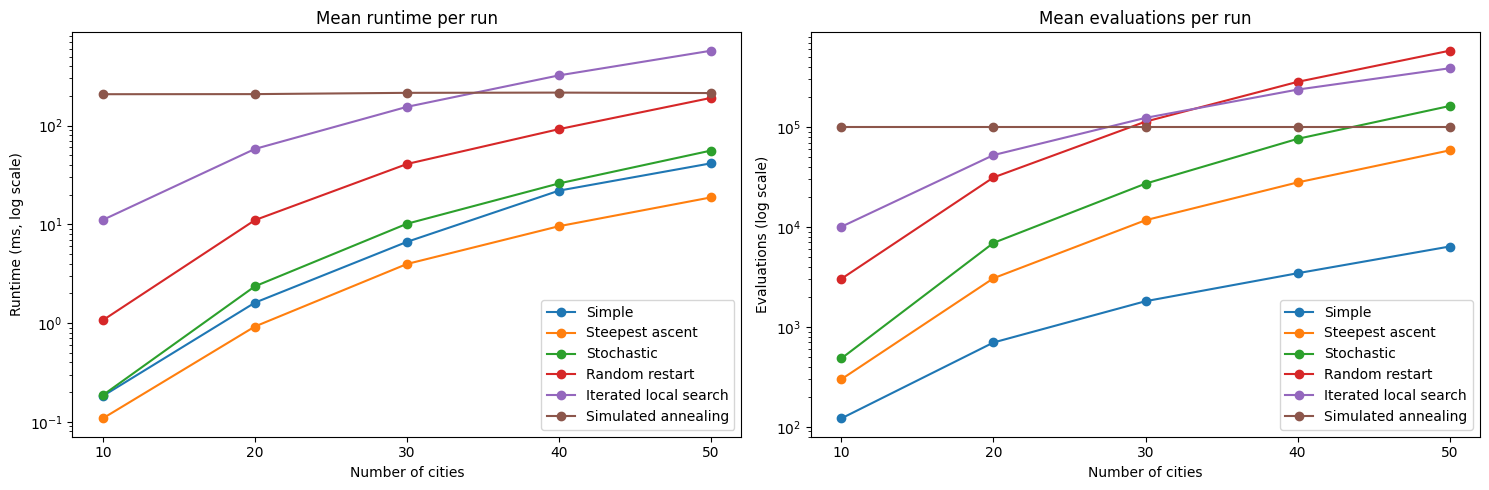

In [38]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ALGO_ORDER:
    sub = df[df["algorithm"] == name].groupby("n")
    ax1.plot(SIZES, sub["runtime"].mean() * 1000, marker="o", label=name)
    ax2.plot(SIZES, sub["evaluations"].mean(), marker="o", label=name)
ax1.set_title("Mean runtime per run")
ax1.set_ylabel("Runtime (ms, log scale)")
ax2.set_title("Mean evaluations per run")
ax2.set_ylabel("Evaluations (log scale)")
for ax in (ax1, ax2):
    ax.set_yscale("log")
    ax.set_xlabel("Number of cities")
    ax.set_xticks(SIZES)
    ax.legend()
plt.tight_layout()
save_fig("scalability")

**Runtime comparison** at each problem size (log scale):

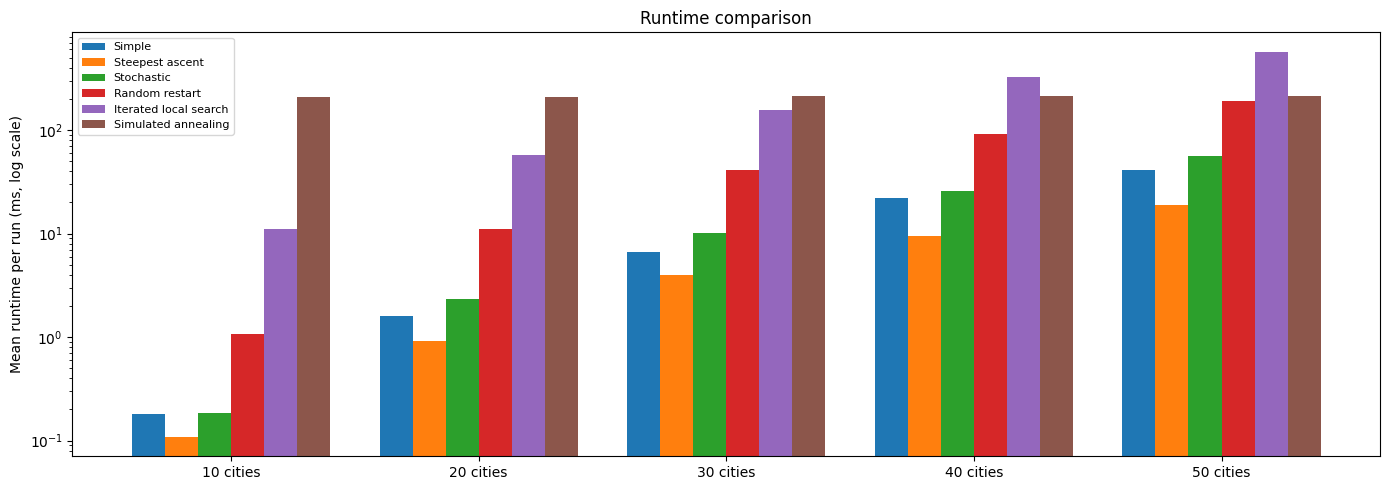

In [39]:
runtime_ms = pivot("runtime") * 1000
x = np.arange(len(SIZES))
width = 0.8 / len(ALGO_ORDER)
plt.figure(figsize=(14, 5))
for k, name in enumerate(ALGO_ORDER):
    plt.bar(x + (k - (len(ALGO_ORDER) - 1) / 2) * width, runtime_ms.loc[name], width, label=name)
plt.xticks(x, [f"{n} cities" for n in SIZES])
plt.yscale("log")
plt.ylabel("Mean runtime per run (ms, log scale)")
plt.title("Runtime comparison")
plt.legend(fontsize=8)
plt.tight_layout()
save_fig("runtime_comparison")

## 12. Convergence behaviour

Each curve is the **best-so-far gap to the reference, averaged over the 20 runs**. The top row uses evaluations on the x-axis, the bottom row uses runtime. Both are on a log scale because the algorithms differ in cost by orders of magnitude.

A curve that drops steeply early converges quickly. A curve that flattens early and stays high has become stuck in a local optimum. A curve that keeps falling is still making progress when the run ends.

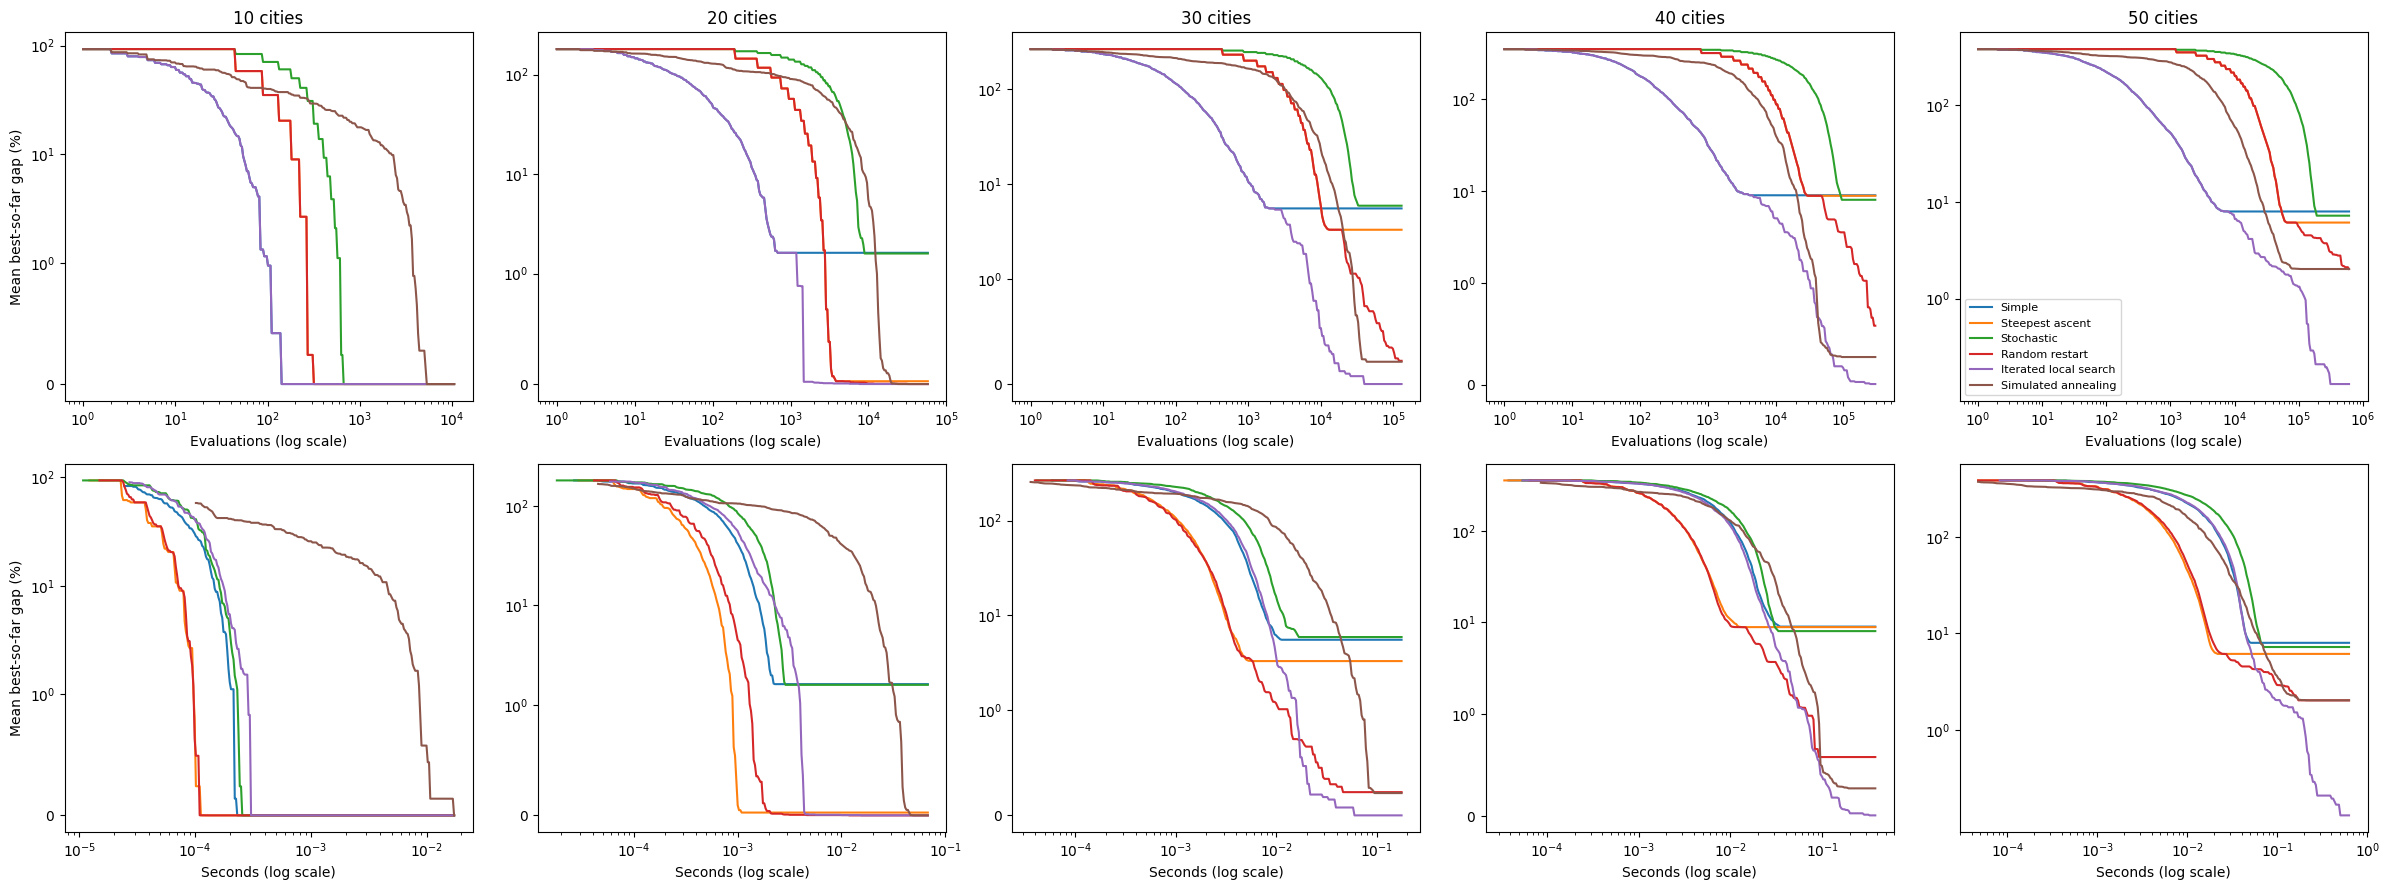

In [40]:
def mean_curve(name, n, column, grid):
    # Average best-so-far gap (%) over all runs, sampled on `grid`
    # column 0 = evaluations, column 1 = seconds
    ref = reference[n]
    curves = []
    for seed in range(RUNS):
        hist = np.array(histories[(name, n, seed)])
        xs, ys = hist[:, column], np.minimum.accumulate(hist[:, 2])
        idx = np.searchsorted(xs, grid, side="right") - 1
        curve = np.where(idx >= 0, ys[np.clip(idx, 0, None)], np.nan)
        curves.append(100 * (curve - ref) / ref)
    # Plain mean: a grid point is only plotted once every run has a value there,
    # otherwise the average would be based on a few early-finishing runs
    return np.mean(np.array(curves), axis=0)


fig, axes = plt.subplots(2, len(SIZES), figsize=(24, 9), sharey="col")
for col, n in enumerate(SIZES):
    keys = [k for k in histories if k[1] == n]
    max_evals = max(histories[k][-1][0] for k in keys)
    max_time = max(histories[k][-1][1] for k in keys)
    grids = [np.geomspace(1, max_evals, 300), np.geomspace(1e-5, max_time, 300)]
    for row, (column, grid, label) in enumerate(zip((0, 1), grids, ("Evaluations", "Seconds"))):
        ax = axes[row, col]
        for name in ALGO_ORDER:
            ax.plot(grid, mean_curve(name, n, column, grid), label=name)
        ax.set_xscale("log")
        ax.set_yscale("symlog", linthresh=1)
        ax.set_xlabel(f"{label} (log scale)")
        if row == 0:
            ax.set_title(f"{n} cities")
        if col == 0:
            ax.set_ylabel("Mean best-so-far gap (%)")
axes[0, -1].legend(fontsize=8)
plt.tight_layout()
save_fig("convergence")

## 13. Robustness across repeated runs

A robust algorithm gives similar results every time it is run. Measures used:
* **Std** – standard deviation of the route length over the 20 runs.
* **CV (%)** – coefficient of variation, std / mean × 100. Unlike std, it can be compared across problem sizes.
* **Worst gap (%)** – the worst of the 20 runs, compared with the reference.
* **Hit rate (%)** – the percentage of runs within 1% of the reference solution.

In [41]:
grouped = df.groupby(["n", "algorithm"], observed=True)
robustness = pd.DataFrame({
    "Std": grouped["length"].std(),
    "CV (%)": 100 * grouped["length"].std() / grouped["length"].mean(),
    "Worst gap (%)": grouped["gap_%"].max(),
    "Hit rate (%)": 100 * grouped["hit"].mean(),
}).round(2)
robustness

Std  CV (%)  Worst gap (%)  Hit rate (%)
n  algorithm                                                        
10 Simple                  0.00    0.00           0.00         100.0
   Steepest ascent         0.00    0.00           0.00         100.0
   Stochastic              0.00    0.00           0.00         100.0
   Random restart          0.00    0.00           0.00         100.0
   Iterated local search   0.00    0.00           0.00         100.0
   Simulated annealing     0.00    0.00           0.00         100.0
20 Simple                 19.01    4.84          17.30          90.0
   Steepest ascent         0.10    0.03           0.05         100.0
   Stochastic             18.65    4.75          16.47          90.0
   Random restart          0.00    0.00           0.00         100.0
   Iterated local search   0.00    0.00           0.00         100.0
   Simulated annealing     0.00    0.00           0.00         100.0
30 Simple                 18.02    3.78          14.54          10.0
   Steepest ascent        18.00    3.86          12.92          35.0
   Stochastic             23.56    4.92          16.88          20.0
   Random restart          2.12    0.47           1.50          90.0
   Iterated local search   0.00    0.00           0.00         100.0
   Simulated annealing     1.08    0.24           0.47         100.0
40 Simple                 28.32    5.31          18.30          10.0
   Steepest ascent        22.01    4.13          17.26           5.0
   Stochastic             30.91    5.84          20.31          25.0
   Random restart          3.55    0.72           2.64          75.0
   Iterated local search   0.15    0.03           0.13         100.0
   Simulated annealing     1.40    0.29           1.11          95.0
50 Simple                 21.01    3.47          15.44           0.0
   Steepest ascent        18.02    3.03          14.83           0.0
   Stochastic             20.89    3.48          14.85           5.0
   Random restart          6.99    1.22           4.49          20.0
   Iterated local search   3.53    0.63           2.11          90.0
   Simulated annealing     7.30    1.28           4.00          30.0

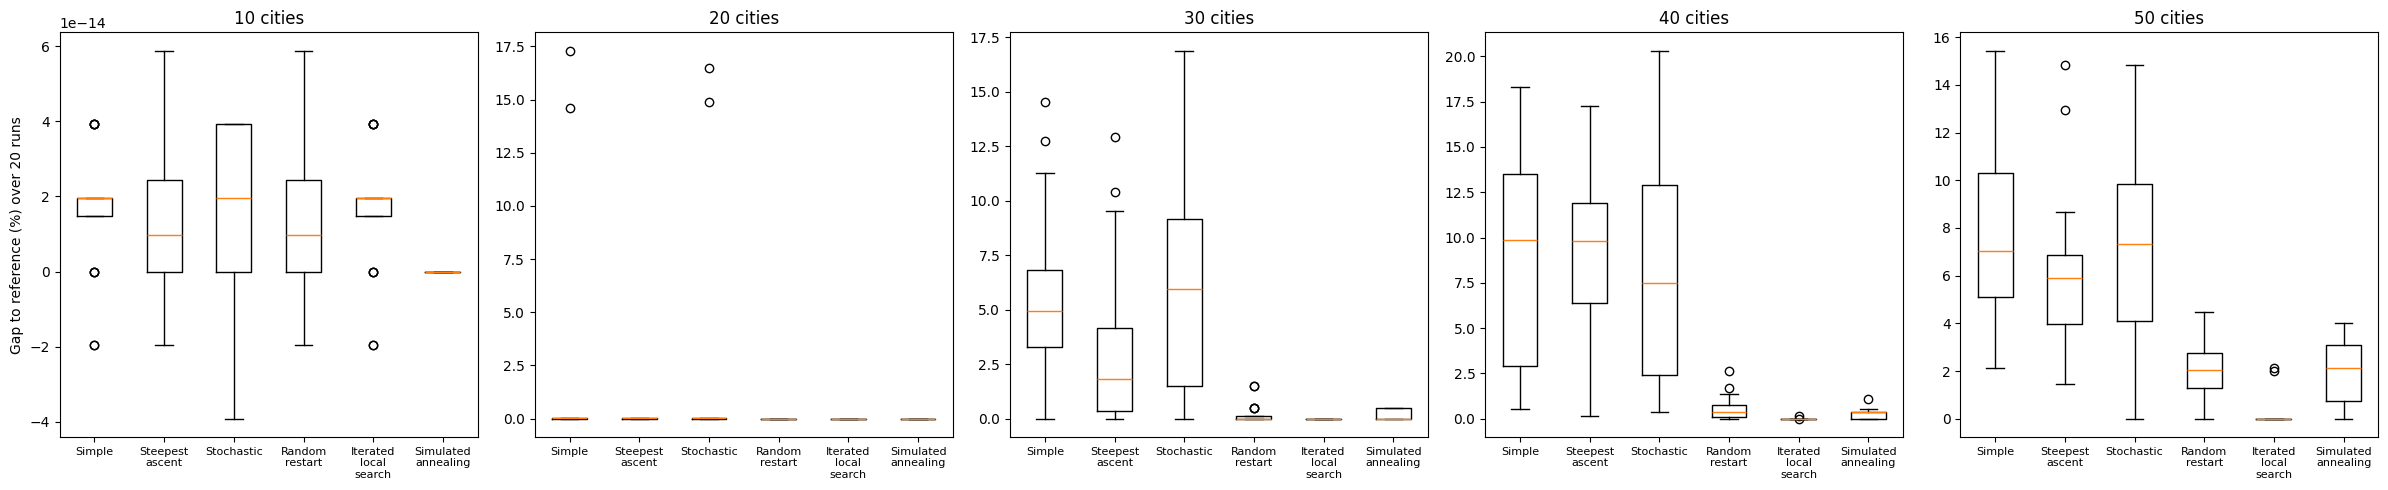

Hit rate: % of runs within 1% of the reference


,10 cities,20 cities,30 cities,40 cities,50 cities
algorithm,,,,,
Simple,100.0,90.0,10.0,10.0,0.0
Steepest ascent,100.0,100.0,35.0,5.0,0.0
Stochastic,100.0,90.0,20.0,25.0,5.0
Random restart,100.0,100.0,90.0,75.0,20.0
Iterated local search,100.0,100.0,100.0,100.0,90.0
Simulated annealing,100.0,100.0,100.0,95.0,30.0


In [42]:
_, axes = plt.subplots(1, len(SIZES), figsize=(24, 5))
for ax, n in zip(axes, SIZES):
    data = [df[(df["n"] == n) & (df["algorithm"] == name)]["gap_%"] for name in ALGO_ORDER]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(ALGO_ORDER) + 1))
    ax.set_xticklabels([name.replace(" ", "\n") for name in ALGO_ORDER], fontsize=8)
    ax.set_title(f"{n} cities")
axes[0].set_ylabel(f"Gap to reference (%) over {RUNS} runs")
plt.tight_layout()
save_fig("robustness_boxplots")

hit_table = (100 * pivot("hit")).round(0)
hit_table.columns = [f"{n} cities" for n in hit_table.columns]
print("Hit rate: % of runs within 1% of the reference")
hit_table

## 14. Statistical hypothesis testing

The tables above show differences in mean route length. With 20 runs per algorithm, though, some of those differences could be due to chance. **Hypothesis tests** check whether a difference is statistically significant, and **effect sizes** show whether it is large enough to matter in practice.

### 14.1 Choosing the tests
Parametric tests such as the t-test and ANOVA assume the results are normally distributed. Route lengths from stochastic search are often skewed: many runs end at similar local optima and a few end much worse. The **Shapiro–Wilk test** checks this for every algorithm and size (H₀: the sample is normally distributed; p < 0.05 means normality is rejected).

In [43]:
ALPHA = 0.05


def test_values(x):
    # Round to 6 d.p. so the same route reached in a different order counts as a tie
    return np.round(np.asarray(x, dtype=float), 6)


normality = {}
for (n, name), x in df.groupby(["n", "algorithm"], observed=True)["length"]:
    x = test_values(x)
    normality[(name, n)] = np.nan if np.ptp(x) == 0 else stats.shapiro(x).pvalue
normality = pd.Series(normality).unstack().reindex(ALGO_ORDER)
normality.columns = [f"{n} cities" for n in normality.columns]

tested = int(normality.notna().sum().sum())
rejected = int((normality < ALPHA).sum().sum())
untestable = int(normality.isna().sum().sum())
print(f"Normality rejected (p < {ALPHA}) for {rejected} of {tested} testable samples.")
print(f"{untestable} samples could not be tested because all 20 runs gave the same length (blank cells).")
normality.round(3)

Normality rejected (p < 0.05) for 12 of 20 testable samples.
10 samples could not be tested because all 20 runs gave the same length (blank cells).


,10 cities,20 cities,30 cities,40 cities,50 cities
Simple,NaN,0.0,0.162,0.072,0.427
Steepest ascent,NaN,0.0,0.001,0.743,0.023
Stochastic,NaN,0.0,0.028,0.141,0.936
Random restart,NaN,NaN,0.000,0.000,0.587
Iterated local search,NaN,NaN,NaN,0.000,0.000
Simulated annealing,NaN,NaN,0.000,0.001,0.091


Normality is rejected for several samples. Many others have no variation at all, because every run found the same route, so no distribution can be assumed. **Non-parametric tests**, which compare the *ranks* of the results rather than their means, are therefore used:

* **Kruskal–Wallis H test** (omnibus, one per problem size). *H₀: all algorithms produce route lengths from the same distribution.* Rejecting H₀ means at least one algorithm differs from the others.
* **Mann–Whitney U test** (pairwise, two-sided). *H₀: the two algorithms produce route lengths from the same distribution.* Every pair of algorithms is compared at each size: 15 pairs per size.
* **Holm–Bonferroni correction.** With 15 comparisons per size, some would look significant by chance alone. Holm's method adjusts the p-values so that the chance of *any* false positive at a given size stays at α = 0.05.
* **Vargha–Delaney A₁₂ effect size.** The probability that a run of algorithm A gives a *shorter* route than a run of algorithm B (0.5 = no difference, 1 = A always better). Conventional thresholds: |A₁₂ − 0.5| < 0.06 negligible, < 0.14 small, < 0.21 medium, otherwise large.

Runs are treated as independent samples. The same seed gives every algorithm the same starting route, but after that each algorithm uses its random numbers differently.

### 14.2 Omnibus test: do the algorithms differ at all?

In [44]:
kw_rows = []
for n in SIZES:
    samples = [test_values(df[(df["n"] == n) & (df["algorithm"] == name)]["length"]) for name in ALGO_ORDER]
    if np.ptp(np.concatenate(samples)) == 0:
        kw_rows.append({"cities": n, "H": np.nan, "p-value": "–",
                        "conclusion": "every run of every algorithm found the same route: no test needed"})
        continue
    h, p = stats.kruskal(*samples)
    kw_rows.append({"cities": n, "H": round(h, 2), "p-value": f"{p:.2e}",
                    "conclusion": "reject H₀: the algorithms differ" if p < ALPHA else "cannot reject H₀"})
pd.DataFrame(kw_rows).set_index("cities")

,H,p-value,conclusion
cities,,,
10,NaN,–,every run of every algorithm found the same ro...
20,39.33,2.04e-07,reject H₀: the algorithms differ
30,70.71,7.28e-14,reject H₀: the algorithms differ
40,87.96,1.80e-17,reject H₀: the algorithms differ
50,83.18,1.81e-16,reject H₀: the algorithms differ


### 14.3 Pairwise comparisons

In [45]:
def a12(x, y):
    # Vargha–Delaney A12: probability that a run from x gives a shorter route than a run from y
    x, y = test_values(x)[:, None], test_values(y)[None, :]
    return ((x < y).sum() + 0.5 * (x == y).sum()) / (x.size * y.size)


def magnitude(a):
    d = abs(a - 0.5)
    return "negligible" if d < 0.06 else "small" if d < 0.14 else "medium" if d < 0.21 else "large"


def holm(pvalues):
    # Holm–Bonferroni step-down adjustment
    p = np.asarray(pvalues, dtype=float)
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted


rows = []
for n in SIZES:
    size_rows = []
    for a, b in itertools.combinations(ALGO_ORDER, 2):
        x = test_values(df[(df["n"] == n) & (df["algorithm"] == a)]["length"])
        y = test_values(df[(df["n"] == n) & (df["algorithm"] == b)]["length"])
        p = 1.0 if np.ptp(np.concatenate([x, y])) == 0 else stats.mannwhitneyu(x, y, alternative="two-sided").pvalue
        size_rows.append({"cities": n, "A": a, "B": b, "p": p, "A12": a12(x, y)})
    for row, p_adj in zip(size_rows, holm([r["p"] for r in size_rows])):
        row["p (Holm)"] = p_adj
        row["significant"] = p_adj < ALPHA
        row["effect"] = magnitude(row["A12"])
        better = row["A"] if row["A12"] > 0.5 else row["B"]
        row["conclusion"] = (f"{better} better ({row['effect']} effect)" if row["significant"]
                             else "no significant difference")
    rows += size_rows

pairwise = pd.DataFrame(rows)
pairwise.to_csv(RESULTS_DIR / "statistical_tests.csv", index=False)
print(f"Saved all {len(pairwise)} pairwise tests to results/statistical_tests.csv")

Saved all 75 pairwise tests to results/statistical_tests.csv


Each heatmap shows A₁₂ for **row algorithm vs column algorithm** at one problem size. Blue means the row algorithm tends to find shorter routes, red means it tends to find longer ones. **\*** marks a significant difference after Holm correction.

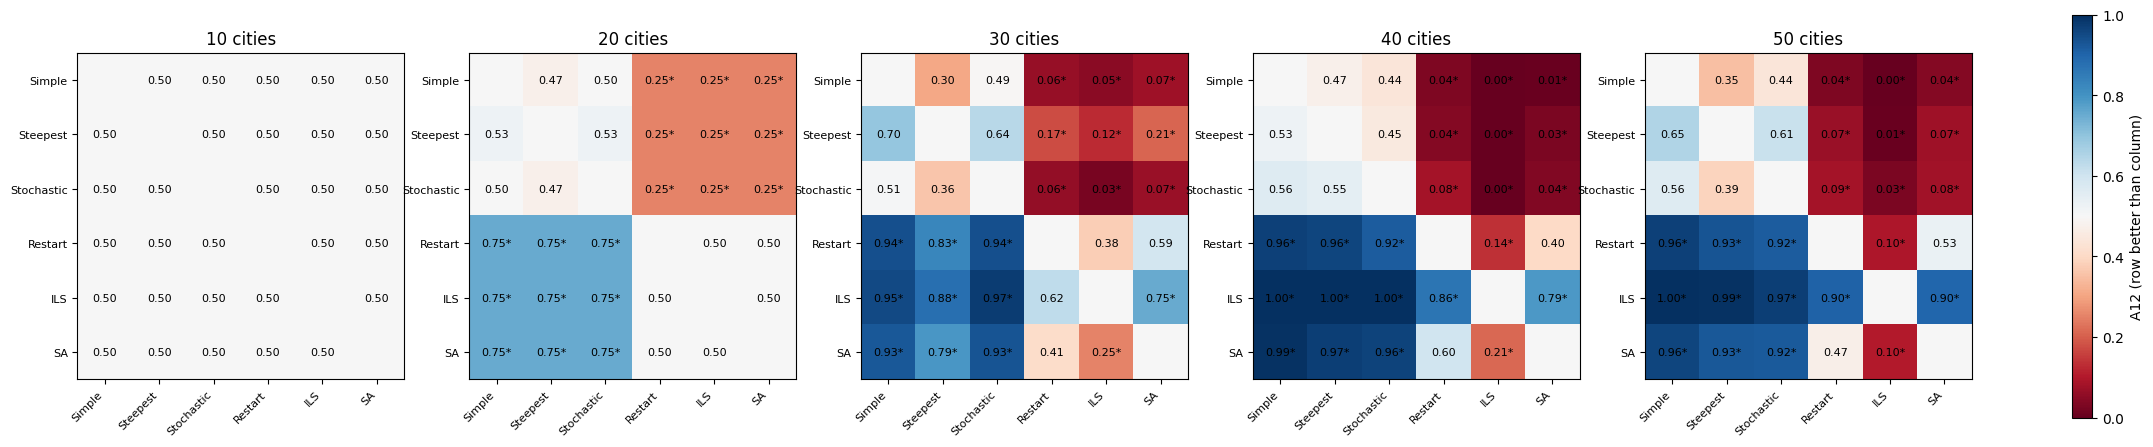

In [46]:
short = {"Simple": "Simple", "Steepest ascent": "Steepest", "Stochastic": "Stochastic",
         "Random restart": "Restart", "Iterated local search": "ILS", "Simulated annealing": "SA"}
labels = [short.get(name, name) for name in ALGO_ORDER]

fig, axes = plt.subplots(1, len(SIZES), figsize=(26, 5.5))
for ax, n in zip(axes, SIZES):
    matrix = np.full((len(ALGO_ORDER), len(ALGO_ORDER)), 0.5)
    stars = np.full(matrix.shape, "", dtype=object)
    for _, r in pairwise[pairwise["cities"] == n].iterrows():
        i, j = ALGO_ORDER.index(r["A"]), ALGO_ORDER.index(r["B"])
        matrix[i, j], matrix[j, i] = r["A12"], 1 - r["A12"]
        stars[i, j] = stars[j, i] = "*" if r["significant"] else ""
    im = ax.imshow(matrix, cmap="RdBu", vmin=0, vmax=1)
    for i in range(len(ALGO_ORDER)):
        for j in range(len(ALGO_ORDER)):
            if i != j:
                ax.text(j, i, f"{matrix[i, j]:.2f}{stars[i, j]}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(f"{n} cities")
fig.colorbar(im, ax=axes, fraction=0.01, label="A12 (row better than column)")
save_fig("pairwise_tests")

**Simulated annealing vs each hill climber**, at every size:

In [47]:
sa_tests = pairwise[(pairwise["B"] == "Simulated annealing") | (pairwise["A"] == "Simulated annealing")].copy()
sa_tests["hill climber"] = np.where(sa_tests["A"] == "Simulated annealing", sa_tests["B"], sa_tests["A"])
# Express A12 as P(SA gives a shorter route than the hill climber)
sa_tests["A12 (SA better)"] = np.where(sa_tests["A"] == "Simulated annealing", sa_tests["A12"], 1 - sa_tests["A12"])
sa_tests["p (Holm)"] = sa_tests["p (Holm)"].map(lambda p: f"{p:.2e}")
sa_tests[["cities", "hill climber", "p (Holm)", "A12 (SA better)", "effect", "conclusion"]] \
    .round(2).set_index(["cities", "hill climber"])

p (Holm)  A12 (SA better)      effect  \
cities hill climber                                                   
10     Simple                 1.00e+00             0.50  negligible   
       Steepest ascent        1.00e+00             0.50  negligible   
       Stochastic             1.00e+00             0.50  negligible   
       Random restart         1.00e+00             0.50  negligible   
       Iterated local search  1.00e+00             0.50  negligible   
20     Simple                 5.01e-03             0.75       large   
       Steepest ascent        5.01e-03             0.75       large   
       Stochastic             5.01e-03             0.75       large   
       Random restart         1.00e+00             0.50  negligible   
       Iterated local search  1.00e+00             0.50  negligible   
30     Simple                 3.05e-05             0.92       large   
       Steepest ascent        6.57e-03             0.79       large   
       Stochastic             2.07e-05             0.93       large   
       Random restart         4.99e-01             0.41       small   
       Iterated local search  2.56e-03             0.25       large   
40     Simple                 1.04e-06             0.99       large   
       Steepest ascent        3.37e-06             0.97       large   
       Stochastic             4.92e-06             0.96       large   
       Random restart         1.00e+00             0.60       small   
       Iterated local search  8.76e-04             0.21       large   
50     Simple                 8.07e-06             0.96       large   
       Steepest ascent        3.21e-05             0.92       large   
       Stochastic             3.70e-05             0.92       large   
       Random restart         1.00e+00             0.47  negligible   
       Iterated local search  3.21e-05             0.10       large   

                                                               conclusion  
cities hill climber                                                        
10     Simple                                   no significant difference  
       Steepest ascent                          no significant difference  
       Stochastic                               no significant difference  
       Random restart                           no significant difference  
       Iterated local search                    no significant difference  
20     Simple                   Simulated annealing better (large effect)  
       Steepest ascent          Simulated annealing better (large effect)  
       Stochastic               Simulated annealing better (large effect)  
       Random restart                           no significant difference  
       Iterated local search                    no significant difference  
30     Simple                   Simulated annealing better (large effect)  
       Steepest ascent          Simulated annealing better (large effect)  
       Stochastic               Simulated annealing better (large effect)  
       Random restart                           no significant difference  
       Iterated local search  Iterated local search better (large effect)  
40     Simple                   Simulated annealing better (large effect)  
       Steepest ascent          Simulated annealing better (large effect)  
       Stochastic               Simulated annealing better (large effect)  
       Random restart                           no significant difference  
       Iterated local search  Iterated local search better (large effect)  
50     Simple                   Simulated annealing better (large effect)  
       Steepest ascent          Simulated annealing better (large effect)  
       Stochastic               Simulated annealing better (large effect)  
       Random restart                           no significant difference  
       Iterated local search  Iterated local search better (large effect)

**Overall ranking.** For each algorithm and size: the number of other algorithms it is significantly better than, minus the number it is significantly worse than. Higher is better; 0 means it is not significantly different from the others on balance.

In [48]:
score = pd.DataFrame(0, index=ALGO_ORDER, columns=SIZES)
for _, r in pairwise[pairwise["significant"]].iterrows():
    winner, loser = (r["A"], r["B"]) if r["A12"] > 0.5 else (r["B"], r["A"])
    score.loc[winner, r["cities"]] += 1
    score.loc[loser, r["cities"]] -= 1
score.columns = [f"{n} cities" for n in SIZES]
score

,10 cities,20 cities,30 cities,40 cities,50 cities
Simple,0,-3,-3,-3,-3
Steepest ascent,0,-3,-3,-3,-3
Stochastic,0,-3,-3,-3,-3
Random restart,0,3,3,2,2
Iterated local search,0,3,4,5,5
Simulated annealing,0,3,2,2,2


### 14.4 Interpretation
**10 cities.** Every algorithm found the optimum in every run, so there is nothing to test: on this size all methods are equally good.

**20–50 cities.** The Kruskal–Wallis test rejects H₀ at every size (p ≤ 2 × 10⁻⁷), so the algorithms do **not** all perform the same. The pairwise tests split them into three consistent groups:

1. **Single-start hill climbers (simple, steepest ascent, stochastic): worst.** They are never significantly different from each other at any size (Holm-adjusted p ≥ 0.14). Each is significantly worse than random restart, ILS and simulated annealing at every size from 20 to 50 cities, always with a large effect. Which single-start variant is used makes no reliable difference; they all stop at the first local optimum.
2. **Random restart and simulated annealing: middle.** These two are **never significantly different** (p ≥ 0.49, effect at most small). Tuned SA therefore gives the same quality as restarting a hill climber ten times, despite a completely different strategy. Both are significantly better than every single-start hill climber, with large effects (for SA, A₁₂ = 0.75–0.99).
3. **Iterated local search: best.** ILS is significantly better than SA at 30, 40 and 50 cities and than random restart at 40 and 50 cities, all with large effects. At 50 cities the probability that a SA run beats an ILS run is only 0.10.

**Statistical vs practical significance.** A significant result with a large A₁₂ means one algorithm wins *consistently*, not that it wins by *much*. At 20 cities, SA is "significantly better than steepest ascent with a large effect", yet the means differ by only 0.03% (386.43 vs 386.53). Steepest ascent sometimes ends slightly above the reference (up to 386.63); SA never does. From 30 cities upwards the differences are also practically meaningful. At 50 cities, the single-start methods average 6–8% above the reference, SA and random restart about 2%, and ILS 0.2%.

**"Not significant" does not mean "equal".** With 20 runs per algorithm the tests can miss small differences. For example, random restart vs ILS at 30 cities (A₁₂ = 0.375 in favour of ILS) is not significant after correction. More runs would be needed to confirm or rule out differences that small.

**Conclusion supported by the tests:** for 30 cities and above, ILS > {simulated annealing ≈ random restart} > {simple ≈ steepest ascent ≈ stochastic}, with each step a large effect.

## 15. Choice of neighbourhood: swap vs 2-opt

The experiments above use 2-opt. To justify that choice, the hill climbers and simulated annealing are re-run on the 50-city instance with the **swap** neighbourhood (10 runs each) and compared with the first 10 runs of the 2-opt experiment.

In [49]:
swap_df, _, _ = run_experiments({name: ALGORITHMS[name] for name in NEIGHBOURHOOD_METHODS},
                                {50: TSP(names, coords, neighbourhood="swap")}, runs=10)
two_opt = df[(df["n"] == 50) & (df["seed"] < 10) & df["algorithm"].isin(NEIGHBOURHOOD_METHODS)]

neighbourhood_table = pd.DataFrame({
    "2-opt mean": two_opt.groupby("algorithm", observed=True)["length"].mean(),
    "swap mean": swap_df.groupby("algorithm")["length"].mean(),
    "2-opt std": two_opt.groupby("algorithm", observed=True)["length"].std(),
    "swap std": swap_df.groupby("algorithm")["length"].std(),
    "2-opt time (ms)": 1000 * two_opt.groupby("algorithm", observed=True)["runtime"].mean(),
    "swap time (ms)": 1000 * swap_df.groupby("algorithm")["runtime"].mean(),
}).loc[NEIGHBOURHOOD_METHODS].round(2)
neighbourhood_table

50 cities: done in 28.1 s


,2-opt mean,swap mean,2-opt std,swap std,2-opt time (ms),swap time (ms)
algorithm,,,,,,
Simple,606.71,863.11,22.03,72.08,39.26,48.01
Steepest ascent,596.18,852.69,18.72,78.39,18.63,98.01
Stochastic,599.79,780.30,18.73,70.71,56.64,257.50
Random restart,570.58,726.83,5.97,26.52,190.51,963.34
Iterated local search,559.86,610.30,0.00,23.67,551.56,1079.90
Simulated annealing,571.67,659.49,8.12,27.57,217.89,365.95


## 16. Best routes found

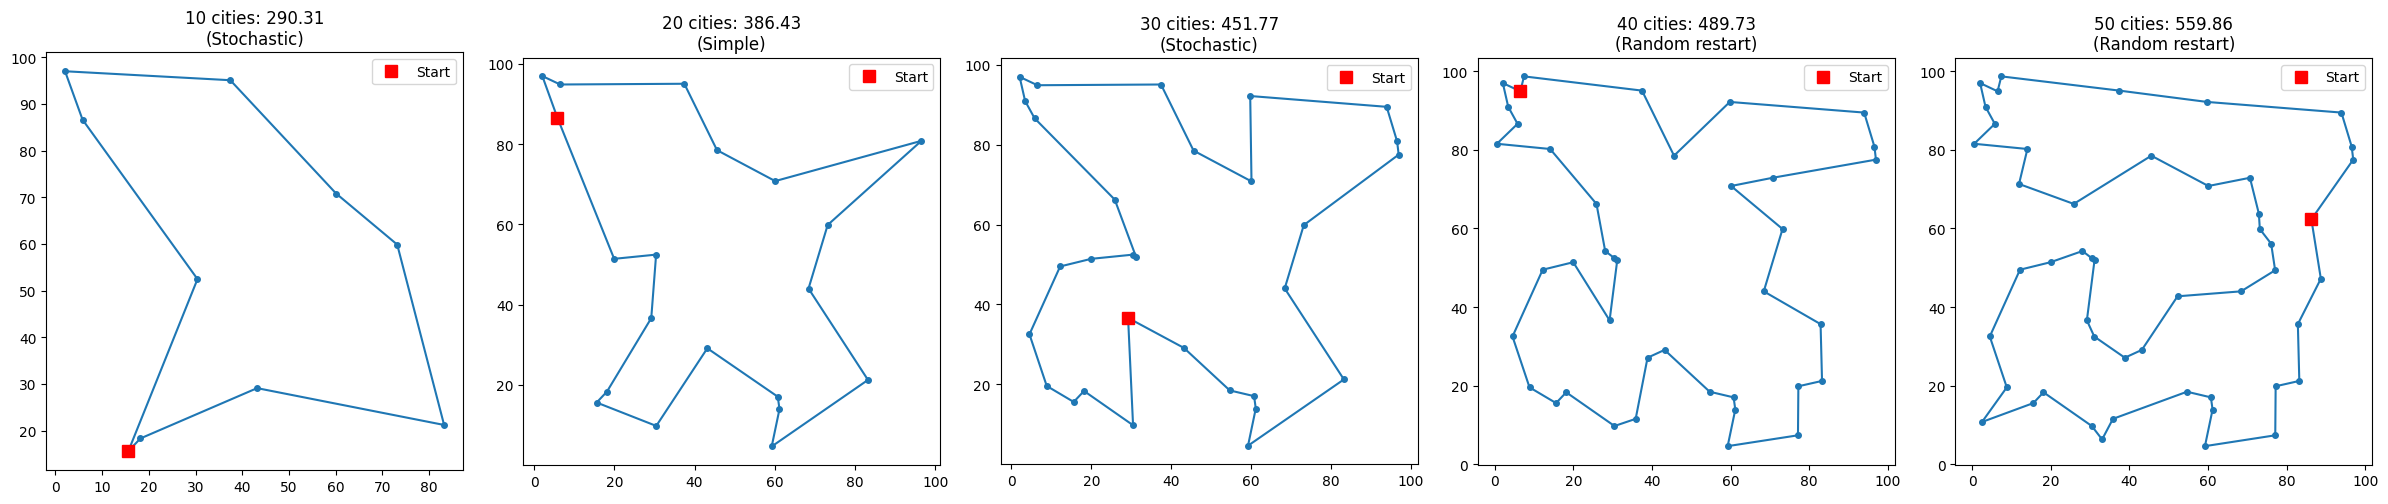

Saved to results/: runs.csv (every run), summary.csv (one row per algorithm and size),
variation.csv, statistical_tests.csv, tuning_runs.csv, best_params.json and figures/*.png


In [50]:
_, axes = plt.subplots(1, len(SIZES), figsize=(24, 5))
for ax, n in zip(axes, SIZES):
    best = df[df["n"] == n].loc[lambda d: d["length"].idxmin()]
    route = routes[(best["algorithm"], n, best["seed"])]
    plot_route(INSTANCES[n], route, f"{n} cities: {best['length']:.2f}\n({best['algorithm']})", ax)
plt.tight_layout()
save_fig("best_routes")

summary = grouped.agg(best=("length", "min"), mean=("length", "mean"), std=("length", "std"),
                      worst=("length", "max"), mean_gap_pct=("gap_%", "mean"),
                      hit_rate=("hit", "mean"), mean_runtime_s=("runtime", "mean"),
                      mean_evaluations=("evaluations", "mean"))
summary.to_csv(RESULTS_DIR / "summary.csv")
print("Saved to results/: runs.csv (every run), summary.csv (one row per algorithm and size),")
print("variation.csv, statistical_tests.csv, tuning_runs.csv, best_params.json and figures/*.png")

## 17. Discussion

The points below were written from the results above (experiment seeds 0–19, tuned parameters from section 9.3). Route lengths, evaluation counts and test results are identical every time the notebook is re-run. Runtimes vary by a few percent between executions, so runtime figures are given approximately.

### Solution quality
* **10 cities is too small to separate the methods:** every algorithm found the true optimum (290.31) in all 20 runs.
* **The single-start hill climbers (simple, steepest ascent, stochastic) degrade quickly as the problem grows.** Their mean gap is under 2% at 20 cities but 3–9% at 30–50 cities.
* **Tuned simulated annealing (SA) and random restart are much better:** their mean gaps are 0.2–0.6% at 30–40 cities and about 2% at 50 cities.
* **ILS is best at every size:** mean gap 0.00, 0.00, 0.00, 0.01 and 0.21%.
* SA, random restart and ILS all found the best known route on every instance at least once. They differ in how *reliably* they find good routes (see Robustness).

### Runtime performance
* The single-start hill climbers take 20–60 ms on 50 cities; random restart and SA about 200 ms; ILS about 600 ms. **ILS buys the best quality with the longest runtime.**
* **SA takes roughly 200–240 ms at every size**, because it always runs a fixed 100,000 iterations. On small instances that is wasteful: at 10 cities it is about 20× slower than ILS for the same, optimal result.
* **Evaluations and runtime do not always agree.** Steepest ascent uses about 9× more evaluations than simple hill climbing on 50 cities, yet it is about twice as *fast*. Likewise, ILS uses fewer evaluations than random restart (≈ 388,000 vs 581,000) but takes about 3× longer. In both cases simple hill climbing is the cause: it rebuilds and shuffles the full list of 1,224 moves after every improvement, and that overhead is not counted as an evaluation. This is why runtime is reported alongside evaluation counts.

### Convergence behaviour
* Per evaluation, **ILS and simple hill climbing improve fastest at the start**, because both take cheap first-improvement steps. Simple hill climbing then **plateaus first**, at a poor local optimum.
* The single-start curves go flat once they reach a local optimum: after that they cannot improve at all.
* **SA converges in a distinctive way.** It improves slowly at first, because it is deliberately accepting worse routes while the temperature is high. It then drops steeply once the temperature has fallen (after roughly 10³ iterations) and levels off towards the end of its budget. Measured by time, SA is the slowest to converge at every size.
* **ILS keeps improving until the end of its run** on 40–50 cities. SA and random restart level off earlier, at about a 2% gap on 50 cities.

### Robustness
* The single-start hill climbers are **not robust** on 30+ cities: coefficient of variation 3–6%, worst runs 13–20% above the reference, and at most 35% of runs within 1% of it.
* Random restart, SA and ILS are far more consistent: CV at most 1.3% for every method at every size.
* **ILS is the most robust:** within 1% of the reference in every run up to 40 cities and 90% of runs at 50 cities (CV ≤ 0.63%). SA reaches 100% up to 30 cities but falls to 30% at 50 cities; random restart falls to 20%.
* Robustness falls with size for every method, because the iteration budgets are fixed and do not grow with the problem.

### Computational scalability
* **Hill climbers:** all grow faster than $n^2$, as the complexity analysis in section 11 predicts. The 2-opt neighbourhood has about $n^2/2$ moves **and** more improving steps are needed for larger routes. Steepest ascent and random restart grow at about $n^{3.3}$ in evaluations.
* **Stochastic hill climbing scales worst** (evaluation exponent ≈ 3.6). Every step scans the whole neighbourhood, and because it picks a random improving move instead of the best one it takes more, smaller steps.
* **SA's cost does not grow with size (exponent ≈ 0)**, because it is set by the number of iterations; each iteration costs $O(1)$, plus $O(n)$ when a move is accepted. This looks like perfect scalability, but its quality drops as $n$ grows (gap 0% → 2.03%): the same budget is spread over a much larger search space.
* **ILS has a low exponent (≈ 2.3)** for the same reason, a fixed number of iterations. Its quality also drops with size, but much less (0% → 0.21%).
* **A fixed budget hides the true scaling cost.** Keeping quality constant as $n$ grows would need more iterations for SA and ILS, so their real cost would grow faster than these exponents suggest.

### Choice of neighbourhood
2-opt beats swap for every method (section 15). Reversing a segment removes crossing edges directly, whereas swapping two cities changes four edges at once and rarely produces an improvement. ILS is the least affected, because its perturbation helps it escape the poorer local optima the swap neighbourhood creates.

### Hill climbing vs simulated annealing
**With the teacher's default settings, SA was no better than a single-start hill climber.** The fast schedule $t = \text{temp}/(i+1)$ with an initial temperature of 100 stops accepting worse moves within the first few hundred iterations, so SA immediately becomes a hill climber (sections 8 and 9.3).

**Tuning the initial temperature to 100,000 changed this completely.** The schedule is the same, but the exploration phase now lasts about 1,000–10,000 iterations instead of about 100. Tuned SA is:
* **significantly better than all three single-start hill climbers** at 20–50 cities, with large effects (section 14);
* **statistically indistinguishable from random restart**, at a similar runtime;
* **significantly worse than ILS** at 30–50 cities.

**Strengths of SA:**
* It is simple to implement.
* Each iteration costs very little, and its runtime is controlled directly by the iteration budget.
* Accepting worse moves lets it escape local optima without restarting.

**Weaknesses of SA:**
* It is **very sensitive to the initial temperature.** In the tuning runs, mean length at 50 cities was 603 with temperature 100, 572 with 100,000 and 792 with 1,000,000.
* The right temperature depends on the scale of the route lengths, so it would need re-tuning for a different dataset.
* With a fixed budget it wastes time on small instances and loses quality on large ones.
* Even when tuned, the fast schedule falls by a factor of 10 with each tenfold increase in iterations, so about 90% of the budget is spent at temperatures where SA is effectively hill climbing.

**Why ILS outperforms SA here.** ILS combines a strong local search (2-opt hill climbing to a local optimum) with a perturbation designed for the TSP (the double bridge). Every ILS iteration therefore ends at a local optimum near a good route. SA instead explores with single random moves and relies on the temperature to escape local optima, and the fast schedule gives it only a short window to do so. A slower schedule (e.g. geometric cooling $t_{i+1} = \alpha t_i$) would spread exploration across the whole budget and would likely narrow the gap.

### Why ILS performs best overall
The TSP landscape has many local optima: the random-restart demonstration in section 6 shows every restart ending at a different one. Single-start methods stop at the first local optimum they reach. Random restart escapes by starting again from scratch, which wastes the good structure already found. SA escapes only while it is hot. ILS escapes with a small, targeted jump and keeps most of the route, so each new climb is short and starts from a good solution.

### Limitations
* All instances come from one dataset (nested subsets of the same 50 cities), so the results may not generalise to differently structured city layouts.
* Parameters were tuned on the 50-city instance only, with 10 runs per setting and a coarse grid (powers of 10 for the temperature). The best values for smaller instances may differ.
* Search budgets were not equalised: at 50 cities SA uses about 100,000 evaluations, ILS about 390,000 and random restart about 580,000. Comparing at an equal time or evaluation budget would be a fairer test of the search strategies themselves.
* For 20–50 cities the reference is the best route *found*, not a proven optimum, so the true gaps may be slightly larger than reported.
* Runtimes are for a pure-Python implementation on one machine. They are useful for comparing the methods with each other, not as absolute speeds.